<center><b><u><h2>Book Recommendation Engine </h2></u></b></center>

## **Table of Contents**

<u><b>Problem Statement </b></u>
- Problem Definition
- Dataset

<u><b>Project Summary </b></u>

<u><b>Requirements </b></u>
- Importing Python libraries
- Custom Python functions

<u><b>Data Description & Transformation </b></u>
- `Books Data`
  - Data View: Load and view data, Column data types, Describe dataset, Count empty rows, Count duplicated rows, Count unique categories
  - Transform Data: Updating rows with data discrepancies,  Data Typecasting, Exclude duplicated entries
- `Ratings Data`
  - Data View: Load and view data, Column data types, Describe dataset, Count empty and duplicated rows, Count unique categories
  - Transform Data: Exclude duplicated entries
- `Readers Data`
  - Data View: Load and view data, Column data types, Describe dataset, Count empty and duplicated rows, Count unique categories
  - Transform Data: Mean-Based Imputation of Missing Age Values, Extract country details from location column & Country column standardization,
                     Exclude duplicated entries, Categorizing readers into age groups
                     
<u><b>Merged Dataset </u></b>
- `Transform Data: Merge & View Data`
  - Rating Metrics Calculation: Total Ratings, Average Ratings, and Weighted Average Ratings
  - Condition-based Data Filtering: Year of Publication of the book is more than 1900,  Books reviewed by active users who have reviewed more than 200 books, Top 10% most reviewed books, Books with number of ratings more than 50, Drop duplicated entries of user id and book title 
  - Text Feature Engineering for Content-Based Retrieval
- `Merged Data View: Books, Ratings, and Readers`: Merged and filtered data view, Column data types, Describe dataset, Count empty and duplicated rows, Count unique categories

<u><b>Data Visualization </u></b>
- Authors with highest number of books written
- Publishers with highest number of books published
- Books with highest number of ratings
- Countries with highest number of readers
- Distribution plot of book ratings
- Distribution plot of reader age
- Year-wise Distribution of Published Books


<u><b>Recommendation System </u></b>
- `Simple Recommendation Engine` (Based on number of ratings & weighted average of ratings)
  - Popularity based recommendation
  - Country based recommendation
  - Author based recommendation
  - Publisher based recommendation
  - Publication Year based recommendation
  - Reader Agegroup based recommendation
- `Advanced Recommendation Engine` (Collaborative filtering, Content filtering, Hybrid filtering)
  - Book Title based recommendation
  - Reader based recommendation 

## Problem Statement

<u>**Problem Definition**</u> <br>  <br>
In the age of digital transformation, platforms like Amazon Kindle, Goodreads, and other online book retailers are revolutionizing how readers discover and engage with literature. Recommender systems, which suggest relevant books based on user preferences, have become a cornerstone of this evolution. They not only enhance user experience but also drive engagement and sales by personalizing recommendations in a way that resonates with individual tastes. 
<br>  <br>
For a company like Amazon Kindle, leveraging recommender systems is crucial to maintaining a competitive edge in the crowded book market. By analyzing user behavior, preferences, and book attributes, these systems can provide tailored recommendations that improve customer satisfaction and increase sales.

<u>**Dataset**</u>

The Book-Crossing dataset provides an in-depth look into user interactions with books, including demographic details, book attributes, and rating information. This dataset consists of, <br>
<u>Users:</u>
Includes anonymized user IDs and demographic information (Location, Age), offering insights into user profiles and preferences. <br>
<u>Books:</u> 
Contains identifiers (ISBN), content details (Title, Author, Year of Publication, Publisher), and cover images from Amazon, enabling a comprehensive understanding of book characteristics. <br>
<u>Ratings:</u> 
Provides feedback on books, with ratings ranging from 1 to 10 or represented implicitly, helping to gauge user appreciation and book popularity.
<br> <br>By analyzing this dataset, a book recommendation system can be developed to deliver personalized book suggestions, optimizing the browsing and purchasing experience. The goal is to enhance user engagement, drive sales, and differentiate the service from competitors by offering highly relevant book recommendations tailored to individual reading preferences.

## Project Summary

- Three datasets, namely Books, Users, and Ratings, were used as the primary inputs for the recommendation system. The datasets contain attributes such as ISBN, Book Title, Author, Year of Publication, Publisher, image URLs, User ID, Book Rating, Location, and Age.
- The data is preprocessed, including data type identification and conversion, handling missing values through imputation and fill methods, removal of duplicate records, correction of spelling inconsistencies and redundancies in categorical variables, and categorization of numerical variables through binning techniques.
- After preprocessing, the Books, Users, and Ratings datasets were merged into a unified dataset. Key metrics such as total ratings, average ratings, and weighted ratings were calculated for each book title. The merged dataset was further refined using the following criteria: Books published after 1900, Books reviewed by active users who have rated more than 200 books, Books belonging to the top 10% most-reviewed titles,
Books with more than 50 ratings, exclude duplicated user-book rating combinations.
- Exploratory Data Analysis was performed to analyse insights from the data. Eight visualizations were created covering the following aspects: Authors with highest number of books written, Publishers with highest number of books published, Books with highest number of ratings, Countries with highest number of readers, Distribution plot of book ratings, Distribution plot of reader age, Year-wise Distribution of Published Books.
-  Two recommendation systems were developed: a Simple Recommendation Engine and an Advanced Recommendation Engine. The Simple Recommendation Engine recommends the top N books based on weighted average ratings and the total number of ratings across various categories, including popularity, country, author, publisher, publication year, and reader age group. An advanced recommendation engine is built using three techniques which are content-based filtering(text-based similarity), collaborative filtering(numerical-based similarity), and hybrid filtering(text & numerical similarity). The advanced recommendation engine provides both book title-based recommendations and reader-based personalized recommendations. Models are evaluated using Precision and recall at top 20 book recommendations.

## Requirements

In [11]:
import numpy as np
import pandas as pd
import random

from IPython.display import Image, HTML, display
from ipywidgets import Dropdown

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt 
plt.rcParams.update({'font.size': 8}) 
import seaborn as sns
import plotly.express as px

pd.set_option('display.max_rows', None)

import pickle
import joblib
import sklearn

import re

from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer

In [12]:
def clean_filename(text):
    if not text:
        return ""
    text = re.sub(r'[\\/:*?"<>|]', '', text) # exclude invalid filename characters
    text = re.sub(r'[\x00-\x1f]', '', text) # exclude control characters (ASCII 0-31)
    text = text.strip() # exclude leading/trailing spaces
    text = text.rstrip('.') # exclude trailing periods

    return text

## Data Description & Transformation

#### Books Data

<u>*Data Description*</u>

`isbn` - International Standard Book Number (ISBN) that uniquely identifies the book <br>
`title`- Title of the book <br>
`author` - Author of the book <br>
`year` - Year of publication of the book <br>
`publisher` - Name of the book publishing company <br>
`image_s` - URL to small-sized book cover image <br>
`image_m` - URL to medium-sized book cover image <br>
`image_l` - URL to large-sized book cover image <br>

##### Data View

*Load and view data*

In [13]:
books = pd.read_csv(r".\input\Books.csv")
books.columns = ['isbn', 'title', 'author', 'year', 'publisher', 'image_s', 'image_m','image_l'] ## renaming columns
books['isbn'] = books['isbn'].str.upper() ## converting isbn to uppercase
print(books.shape) ## checking the shape of the dataset
display(books.head(1)) ## displaying the first row of the dataset

(271360, 8)


,isbn,title,author,year,publisher,image_s,image_m,image_l
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...


*Column data types*

In [14]:
display(books.info()) ## displaying the column data type and null counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271360 entries, 0 to 271359
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   isbn       271360 non-null  object
 1   title      271360 non-null  object
 2   author     271358 non-null  object
 3   year       271360 non-null  object
 4   publisher  271358 non-null  object
 5   image_s    271360 non-null  object
 6   image_m    271360 non-null  object
 7   image_l    271357 non-null  object
dtypes: object(8)
memory usage: 16.6+ MB


None

*Describe dataset*

In [16]:
## displaying the statistical summary of the dataset
display(books.describe(include=['int','float']).T)
display(books.describe(include=['O']).T)

,count,unique,top,freq
isbn,271360,271046,039475929X,2
title,271360,242135,Selected Poems,27
author,271358,102022,Agatha Christie,632
year,271360,202,2002,13903
publisher,271358,16807,Harlequin,7535
image_s,271360,271044,http://images.amazon.com/images/P/155936078X.0...,2
image_m,271360,271044,http://images.amazon.com/images/P/155936078X.0...,2
image_l,271357,271041,http://images.amazon.com/images/P/155936078X.0...,2


*Count empty rows*

In [17]:
## count the number of empty rows in each column
print(books.isnull().sum())

## identify empty records of author , publisher and images
display(books.loc[(books['author'].isnull()),: ])
display(books.loc[(books['publisher'].isnull()),: ])
display(books.loc[(books['image_l'].isnull()),: ])

isbn         0
title        0
author       2
year         0
publisher    2
image_s      0
image_m      0
image_l      3
dtype: int64


,isbn,title,author,year,publisher,image_s,image_m,image_l
118033,0751352497,A+ Quiz Masters:01 Earth,NaN,1999,Dorling Kindersley,http://images.amazon.com/images/P/0751352497.0...,http://images.amazon.com/images/P/0751352497.0...,http://images.amazon.com/images/P/0751352497.0...
187689,9627982032,The Credit Suisse Guide to Managing Your Perso...,NaN,1995,Edinburgh Financial Publishing,http://images.amazon.com/images/P/9627982032.0...,http://images.amazon.com/images/P/9627982032.0...,http://images.amazon.com/images/P/9627982032.0...


,isbn,title,author,year,publisher,image_s,image_m,image_l
128890,193169656X,Tyrant Moon,Elaine Corvidae,2002,NaN,http://images.amazon.com/images/P/193169656X.0...,http://images.amazon.com/images/P/193169656X.0...,http://images.amazon.com/images/P/193169656X.0...
129037,1931696993,Finders Keepers,Linnea Sinclair,2001,NaN,http://images.amazon.com/images/P/1931696993.0...,http://images.amazon.com/images/P/1931696993.0...,http://images.amazon.com/images/P/1931696993.0...


,isbn,title,author,year,publisher,image_s,image_m,image_l
209538,078946697X,"DK Readers: Creating the X-Men, How It All Beg...",2000,DK Publishing Inc,http://images.amazon.com/images/P/078946697X.0...,http://images.amazon.com/images/P/078946697X.0...,http://images.amazon.com/images/P/078946697X.0...,NaN
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers\"";Jean-M...",2003,Gallimard,http://images.amazon.com/images/P/2070426769.0...,http://images.amazon.com/images/P/2070426769.0...,http://images.amazon.com/images/P/2070426769.0...,NaN
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Book...",2000,DK Publishing Inc,http://images.amazon.com/images/P/0789466953.0...,http://images.amazon.com/images/P/0789466953.0...,http://images.amazon.com/images/P/0789466953.0...,NaN


*Count duplicated rows*

In [18]:
## count the number of duplicate rows in the column 
print(books.duplicated().sum())

## view the first 2 duplicate rows in the dataset
print(books[books.duplicated()].shape)
books[books.duplicated()].head(2)

194
(194, 8)


,isbn,title,author,year,publisher,image_s,image_m,image_l
6635,002542730X,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...
11925,014062080X,The Scarlet Letter (Penguin Popular Classics),Nathaniel Hawthorne,1994,Penguin Books Ltd,http://images.amazon.com/images/P/014062080X.0...,http://images.amazon.com/images/P/014062080X.0...,http://images.amazon.com/images/P/014062080X.0...


*Count unique categories of column*

In [19]:
summary = pd.DataFrame([(column, len(books[column].unique()),books[column].dtype) for column in list(books.columns)],columns =['column_name','Unique_len','dtype'])
summary

,column_name,Unique_len,dtype
0,isbn,271046,object
1,title,242135,object
2,author,102023,object
3,year,202,object
4,publisher,16808,object
5,image_s,271044,object
6,image_m,271044,object
7,image_l,271042,object


##### Transform Data

*Updating rows with data discrepencies*

In [20]:
print(books['year'].unique())
display(books[books['year'] == 'DK Publishing Inc'])
display(books[books['year'] == 'Gallimard'])

#### updating the values of the rows
books.loc[209538, 'title'] = 'DK Readers: Creating the X-Men, How It All Began (Level 4: Proficient Readers)'
books.loc[209538, 'author'] = 'Michael Teitelbaum'
books.loc[209538, 'year'] = 2000
books.loc[209538, 'publisher'] = 'DK Publishing Inc'

books.loc[221678, 'title'] =  'DK Readers: Creating the X-Men, How Comic Books Come to Life (Level 4: Proficient Readers)'
books.loc[221678, 'author'] = 'James Buckley'
books.loc[221678, 'year'] = 2000
books.loc[221678, 'publisher'] = 'DK Publishing Inc'

books.loc[220731, 'title'] = "Peuple du ciel, suivi de 'Les Bergers"
books.loc[220731, 'author'] = 'Jean-Marie Gustave Le ClÃ?Â©zio'
books.loc[220731, 'year'] = 2003
books.loc[220731, 'publisher'] = 'Gallimard'

print(books['year'].unique())
display(books.iloc[209538:209539,:])
display(books.iloc[221678:221679,:])
display(books.iloc[220731:220732,:])

[2002 2001 1991 1999 2000 1993 1996 1988 2004 1998 1994 2003 1997 1983
 1979 1995 1982 1985 1992 1986 1978 1980 1952 1987 1990 1981 1989 1984 0
 1968 1961 1958 1974 1976 1971 1977 1975 1965 1941 1970 1962 1973 1972
 1960 1966 1920 1956 1959 1953 1951 1942 1963 1964 1969 1954 1950 1967
 2005 1957 1940 1937 1955 1946 1936 1930 2011 1925 1948 1943 1947 1945
 1923 2020 1939 1926 1938 2030 1911 1904 1949 1932 1928 1929 1927 1931
 1914 2050 1934 1910 1933 1902 1924 1921 1900 2038 2026 1944 1917 1901
 2010 1908 1906 1935 1806 2021 '2000' '1995' '1999' '2004' '2003' '1990'
 '1994' '1986' '1989' '2002' '1981' '1993' '1983' '1982' '1976' '1991'
 '1977' '1998' '1992' '1996' '0' '1997' '2001' '1974' '1968' '1987' '1984'
 '1988' '1963' '1956' '1970' '1985' '1978' '1973' '1980' '1979' '1975'
 '1969' '1961' '1965' '1939' '1958' '1950' '1953' '1966' '1971' '1959'
 '1972' '1955' '1957' '1945' '1960' '1967' '1932' '1924' '1964' '2012'
 '1911' '1927' '1948' '1962' '2006' '1952' '1940' '1951' '1931' '1954

,isbn,title,author,year,publisher,image_s,image_m,image_l
209538,078946697X,"DK Readers: Creating the X-Men, How It All Beg...",2000,DK Publishing Inc,http://images.amazon.com/images/P/078946697X.0...,http://images.amazon.com/images/P/078946697X.0...,http://images.amazon.com/images/P/078946697X.0...,NaN
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Book...",2000,DK Publishing Inc,http://images.amazon.com/images/P/0789466953.0...,http://images.amazon.com/images/P/0789466953.0...,http://images.amazon.com/images/P/0789466953.0...,NaN


,isbn,title,author,year,publisher,image_s,image_m,image_l
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers\"";Jean-M...",2003,Gallimard,http://images.amazon.com/images/P/2070426769.0...,http://images.amazon.com/images/P/2070426769.0...,http://images.amazon.com/images/P/2070426769.0...,NaN


[2002 2001 1991 1999 2000 1993 1996 1988 2004 1998 1994 2003 1997 1983
 1979 1995 1982 1985 1992 1986 1978 1980 1952 1987 1990 1981 1989 1984 0
 1968 1961 1958 1974 1976 1971 1977 1975 1965 1941 1970 1962 1973 1972
 1960 1966 1920 1956 1959 1953 1951 1942 1963 1964 1969 1954 1950 1967
 2005 1957 1940 1937 1955 1946 1936 1930 2011 1925 1948 1943 1947 1945
 1923 2020 1939 1926 1938 2030 1911 1904 1949 1932 1928 1929 1927 1931
 1914 2050 1934 1910 1933 1902 1924 1921 1900 2038 2026 1944 1917 1901
 2010 1908 1906 1935 1806 2021 '2000' '1995' '1999' '2004' '2003' '1990'
 '1994' '1986' '1989' '2002' '1981' '1993' '1983' '1982' '1976' '1991'
 '1977' '1998' '1992' '1996' '0' '1997' '2001' '1974' '1968' '1987' '1984'
 '1988' '1963' '1956' '1970' '1985' '1978' '1973' '1980' '1979' '1975'
 '1969' '1961' '1965' '1939' '1958' '1950' '1953' '1966' '1971' '1959'
 '1972' '1955' '1957' '1945' '1960' '1967' '1932' '1924' '1964' '2012'
 '1911' '1927' '1948' '1962' '2006' '1952' '1940' '1951' '1931' '1954

,isbn,title,author,year,publisher,image_s,image_m,image_l
209538,078946697X,"DK Readers: Creating the X-Men, How It All Beg...",Michael Teitelbaum,2000,DK Publishing Inc,http://images.amazon.com/images/P/078946697X.0...,http://images.amazon.com/images/P/078946697X.0...,NaN


,isbn,title,author,year,publisher,image_s,image_m,image_l
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Book...",James Buckley,2000,DK Publishing Inc,http://images.amazon.com/images/P/0789466953.0...,http://images.amazon.com/images/P/0789466953.0...,NaN


,isbn,title,author,year,publisher,image_s,image_m,image_l
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers",Jean-Marie Gustave Le ClÃ?Â©zio,2003,Gallimard,http://images.amazon.com/images/P/2070426769.0...,http://images.amazon.com/images/P/2070426769.0...,NaN


*Data Typecasting*

In [21]:
books['year'] = books['year'].astype(int) ## converting the year column to integer data type
display(books.info()) ## displaying the column data type and null counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271360 entries, 0 to 271359
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   isbn       271360 non-null  object
 1   title      271360 non-null  object
 2   author     271358 non-null  object
 3   year       271360 non-null  int64 
 4   publisher  271358 non-null  object
 5   image_s    271360 non-null  object
 6   image_m    271360 non-null  object
 7   image_l    271357 non-null  object
dtypes: int64(1), object(7)
memory usage: 16.6+ MB


None

*Exclude duplicated entries*

In [22]:
books.drop_duplicates(keep="first",inplace=True) ## dropping the duplicate rows in the dataset
print(books.shape)

(271047, 8)


#### Ratings Data

<u>*Data Description*</u>

`user_id` - Unique identifier of the book reader <br>
`isbn` - International Standard Book Number (ISBN) that uniquely identifies the book <br>
`ratings` - Reader's rating of the book on a scale from 0 to 10 

##### Data View

*Load and view data*

In [23]:
ratings = pd.read_csv(r".\input\Ratings.csv")
ratings.columns = ['user_id', 'isbn', 'ratings'] ## renaming columns
ratings['isbn'] = ratings['isbn'].str.upper() ## converting isbn to uppercase
print(ratings.shape) ## checking the shape of the dataset
display(ratings.head(1)) ## displaying the first row of the dataset

(1149780, 3)


,user_id,isbn,ratings
0,276725,034545104X,0


*Column data types*

In [24]:
display(ratings.info())  ## displaying the column data type and null counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1149780 entries, 0 to 1149779
Data columns (total 3 columns):
 #   Column   Non-Null Count    Dtype 
---  ------   --------------    ----- 
 0   user_id  1149780 non-null  int64 
 1   isbn     1149780 non-null  object
 2   ratings  1149780 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 26.3+ MB


None

*Describe dataset*

In [25]:
## displaying the statistical summary of the dataset
display(ratings.describe(include=['int','float']).T)
display(ratings.describe(include='O').T) 

,count,mean,std,min,25%,50%,75%,max
user_id,1149780.0,140386.395126,80562.277718,2.0,70345.0,141010.0,211028.0,278854.0
ratings,1149780.0,2.866950,3.854184,0.0,0.0,0.0,7.0,10.0


,count,unique,top,freq
isbn,1149780,340218,0971880107,2502


*Count empty and duplicated rows*

In [26]:
## count the number of empty rows in each column
print(ratings.isnull().sum())

## count the number of duplicated rows in each column
print(ratings.duplicated().sum())

user_id    0
isbn       0
ratings    0
dtype: int64
0


*Count unique categories of column*

In [27]:
summary = pd.DataFrame([(column, len(ratings[column].unique()),ratings[column].dtype) for column in list(ratings.columns)],columns =['column_name','Unique_len','dtype'])
summary

,column_name,Unique_len,dtype
0,user_id,105283,int64
1,isbn,340218,object
2,ratings,11,int64


##### Transform Data

*Exclude duplicated entries*

In [28]:
ratings.drop_duplicates(keep="first",inplace=True) ## dropping the duplicate rows in the dataset
print(ratings.shape)

(1149780, 3)


#### Readers Data

<u>*Data Description*</u>

`user_id` - Unique identifier of the book reader <br>
`location` - Geographic location of the book reader <br>
`age` - Age of the book reader in years

##### Data View

*Load and view data*

In [29]:
users = pd.read_csv(r".\input\Users.csv")
users.columns = ['user_id', 'location', 'age']  ## renaming columns
print(users.shape)  ## checking the shape of the dataset
display(users.head(1))  ## displaying the first row of the dataset

(278858, 3)


,user_id,location,age
0,1,"nyc, new york, usa",NaN


*Column data types*

In [30]:
display(users.info()) ## displaying the column data type and null counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 278858 entries, 0 to 278857
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   user_id   278858 non-null  int64  
 1   location  278858 non-null  object 
 2   age       168096 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 6.4+ MB


None

*Describe dataset*

In [31]:
## displaying the statistical summary of the dataset
display(users.describe(include=['int','float']).T)
display(users.describe(include='O').T)

,count,mean,std,min,25%,50%,75%,max
user_id,278858.0,139429.500000,80499.515020,1.0,69715.25,139429.5,209143.75,278858.0
age,168096.0,34.751434,14.428097,0.0,24.00,32.0,44.00,244.0


,count,unique,top,freq
location,278858,57339,"london, england, united kingdom",2506


*Count empty and duplicated rows*

In [32]:
## count the number of empty rows in each column
print(users.isnull().sum())

## count the number of duplicated rows in each column
print(users.duplicated().sum())

user_id          0
location         0
age         110762
dtype: int64
0


*Count unique categories of column*

In [33]:
summary = pd.DataFrame([(column, len(users[column].unique()),users[column].dtype) for column in list(users.columns)],columns =['column_name','Unique_len','dtype'])
summary

,column_name,Unique_len,dtype
0,user_id,278858,int64
1,location,57339,object
2,age,166,float64


##### Transform Data

*Mean-Based Imputation of Missing Age Values*

In [34]:
print(users.isnull().sum())
users['age'] = users['age'].fillna((users['age'].mean())) ## filling the empty values in the age column with the mean of the column
print(users.isnull().sum())

user_id          0
location         0
age         110762
dtype: int64
user_id     0
location    0
age         0
dtype: int64


*Extract country details from location column & Country column standardization*

In [35]:
## extracting the country name from the location column
print(len(users['location'].unique()))
users['country'] = users['location'].astype(str).apply(lambda x:x.split(',')[2] if len(x.split(','))==3 else np.nan)
users['country'] = users['country'].apply(lambda x : str(x).replace(' ','').replace('"','') )
print(users['country'].nunique()) ## checking the number of unique values in the country column

57339
611


In [36]:
## cleaning the country column to standardized country names
country_mappings_df = pd.read_excel(r".\input\transformed\countries.xlsx", sheet_name='country_mapped') 
country_mappings = dict(country_mappings_df.to_dict(orient='split')['data']) ## converting the country mappings dataframe to a dictionary
print(len(country_mappings))

users['country_cleaned'] = users['country'].apply(lambda x: country_mappings[x] if x in country_mappings.keys() else np.nan)
users = users.drop(columns=['location', 'country']).rename(columns={'country_cleaned':'country'})
print(users.shape)
display(users.head())

609
(278858, 3)


,user_id,age,country
0,1,34.751434,United States
1,2,18.000000,United States
2,3,34.751434,Russia
3,4,17.000000,Portugal
4,5,34.751434,United Kingdom


In [37]:
## count the number of empty rows in each column
display(users.isna().sum())

user_id       0
age           0
country    6178
dtype: int64

*Exclude duplicated entries*

In [38]:
users.drop_duplicates(keep="first",inplace=True)
print(users.shape)

(278858, 3)


*Categorizing readers into age groups*

In [39]:
def age_group(age):
  if age<13:
    x='Children'
  elif age>=13 and age<18:
    x='Teens'
  elif age>=18 and age<36:
    x='Youth'
  elif age>=36 and age<56:
    x='Middle aged adults'
  else:
    x='Elderly'
  return x

users['age_group']=users['age'].apply(lambda x: age_group(x))
users = users[['user_id','age','age_group', 'country']]
print(users.shape)
users.head(2)

(278858, 4)


,user_id,age,age_group,country
0,1,34.751434,Youth,United States
1,2,18.000000,Youth,United States


## Merged Dataset

<u>*Data Description*</u>

`user_id` - Unique identifier of the book reader <br>
`isbn` - International Standard Book Number (ISBN) that uniquely identifies the book <br>
`ratings` - Reader's rating of the book on a scale from 0 to 10  <br>
`age` - Age of the book reader in years <br>
`age_group` - Categorized age segment of the book reader such as Children, Teens, Youth, Middle aged Adults or Elderly<br>
`country` - Country of the book reader <br>
`title`- Title of the book <br>
`author` - Author of the book <br>
`year` - Year of publication of the book <br>
`publisher` - Name of the book publishing company <br>
`image_s` - URL to small-sized book cover image <br>
`image_m` - URL to medium-sized book cover image <br>
`image_l` - URL to large-sized book cover image <br>


#### Transform Data

*Merge and view data*

In [40]:
### merge books, ratings, and users datasets into one.
books_with_rating = ratings.merge(users, on='user_id').merge(books,on='isbn')
print(books_with_rating.shape)
display(books_with_rating.head(2))

(1031273, 13)


,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l
0,276725,034545104X,0,34.751434,Youth,United States,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...
1,276726,0155061224,5,34.751434,Youth,United States,Rites of Passage,Judith Rae,2001,Heinle,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...


##### Rating Metrics Calculation: Total Ratings, Average Ratings, and Weighted Average Ratings


`num_ratings`: Total number of user ratings by book title <br>

`avg_ratings`: Average of the user ratings by book title  <br>

`weighted_rating`: (average_rating * number_of_ratings + minimum_threshold * average_rating_total)/(number_of_ratings + minimum_threshold) <br>
where,
- *average_rating*: Average rating of a book title.
- *number_of_ratings*: Number of ratings received by a book title.
- *minimum_threshold*: Minimum number of votes required for validation. 100 is the threshold considered.
- *average_rating_total*: Average rating across all book titles.

In [41]:
def calcWeightedRating(row, avgRating, numOfRatings, minThres, avgRating_all):
    weightedRating = ((row[avgRating] * row[numOfRatings]) + 
      (minThres * avgRating_all))/(row[numOfRatings] + minThres)
    return weightedRating

In [42]:
### number and average of ratings by book title
ratings_count = books_with_rating.groupby(['title'])['ratings'].count().reset_index().rename(columns={'ratings':'num_ratings'})
avgRating_all = round(ratings_count['num_ratings'].mean(),2)
avg_ratings = books_with_rating.groupby(['title'])['ratings'].mean().reset_index().rename(columns={'ratings':'avg_ratings'})

books_with_rating = books_with_rating.merge(ratings_count, on='title')
books_with_rating = books_with_rating.merge(avg_ratings, on='title')
print(books_with_rating.shape)

### weighted average book rating calculation
books_with_rating['weighted_rating'] = books_with_rating.apply(lambda x: calcWeightedRating(x, 'avg_ratings', 'num_ratings', 100, avgRating_all),axis=1)
# books_with_rating = books_with_rating.sort_values('weighted_rating', ascending=False)
print(books_with_rating.shape)
books_with_rating.head()

(1031273, 15)
(1031273, 16)


,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l,num_ratings,avg_ratings,weighted_rating
0,276725,034545104X,0,34.751434,Youth,United States,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...,60,2.933333,3.775000
1,276726,0155061224,5,34.751434,Youth,United States,Rites of Passage,Judith Rae,2001,Heinle,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...,14,1.714286,3.964912
2,276727,0446520802,0,16.000000,Teens,Australia,The Notebook,Nicholas Sparks,1996,Warner Books,http://images.amazon.com/images/P/0446520802.0...,http://images.amazon.com/images/P/0446520802.0...,http://images.amazon.com/images/P/0446520802.0...,650,3.560000,3.656000
3,276729,052165615X,3,16.000000,Teens,Croatia,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,http://images.amazon.com/images/P/052165615X.0...,http://images.amazon.com/images/P/052165615X.0...,http://images.amazon.com/images/P/052165615X.0...,1,3.000000,4.267327
4,276729,0521795028,6,16.000000,Teens,Croatia,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,http://images.amazon.com/images/P/0521795028.0...,http://images.amazon.com/images/P/0521795028.0...,http://images.amazon.com/images/P/0521795028.0...,1,6.000000,4.297030


##### Condition-based Data Filtering

Dataset is filtered to meet the below criteria:
- Books published after 1900
- Books reviewed by active users who have rated more than 200 books
- Top 10% most reviewed books
- Books with more than 50 ratings
- Exclude duplicate user-book rating combinations.

In [43]:
#### user rating count
user_ratings_count = ratings['user_id'].value_counts().reset_index().rename(columns={'count':'num_ratings'})
print(user_ratings_count.shape)
display(user_ratings_count.head(1))
display(user_ratings_count.describe().T)

## active users who have reviewed more than 200 books
active_users = np.array(user_ratings_count[user_ratings_count['num_ratings'] > 200]['user_id'])
print(active_users.shape)

print('----'*50)
print('----'*50)

#### books rating count
books_ratings_count = ratings['isbn'].value_counts().reset_index().rename(columns={'count':'num_ratings'})
print(books_ratings_count.shape)
display(books_ratings_count.head(1))
display(books_ratings_count.describe().T)

## active books - top 10% most frequently rated books
active_books = books_ratings_count.head(int(0.1*len(books_ratings_count)))['isbn']
print(active_books.shape)

(105283, 2)


,user_id,num_ratings
0,11676,13602


,count,mean,std,min,25%,50%,75%,max
user_id,105283.0,139474.738619,80574.738184,2.0,69376.0,139146.0,209643.5,278854.0
num_ratings,105283.0,10.920851,90.562825,1.0,1.0,1.0,4.0,13602.0


(899,)
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
(340218, 2)


,isbn,num_ratings
0,0971880107,2502


,count,mean,std,min,25%,50%,75%,max
num_ratings,340218.0,3.379539,12.448198,1.0,1.0,1.0,2.0,2502.0


(34021,)


In [44]:
### book year more than 1900
books_with_rating_fil = books_with_rating[books_with_rating['year'] >= 1900]
display(books_with_rating_fil.head(1))
print(books_with_rating_fil.shape)

#### active users who have reviewed more than 200 books
books_with_rating_fil = books_with_rating_fil[books_with_rating_fil['user_id'].isin(active_users)]
display(books_with_rating_fil.head(1))
print(books_with_rating_fil.shape)

### active books - top 10 % most reviewed books
books_with_rating_fil =  books_with_rating_fil[books_with_rating_fil['isbn'].isin(active_books)]
display(books_with_rating_fil.head(1))
print(books_with_rating_fil.shape)

#### books with ratings more than 50
books_with_rating_fil = books_with_rating_fil[books_with_rating_fil['num_ratings'] >= 50]
display(books_with_rating_fil.head(1))
print(books_with_rating_fil.shape)

#### drop duplicated entries of user id and title
books_with_rating_fil = books_with_rating_fil.drop_duplicates(['user_id', 'title']).reset_index().iloc[:,1:]
display(books_with_rating_fil.head(1))
print(books_with_rating_fil.shape)

pickle.dump(books_with_rating_fil, open(r'.\input\transformed\books_with_rating_fil.pkl','wb'))

,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l,num_ratings,avg_ratings,weighted_rating
0,276725,034545104X,0,34.751434,Youth,United States,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...,60,2.933333,3.775


(1017260, 16)


,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l,num_ratings,avg_ratings,weighted_rating
1150,277427,002542730X,10,48.0,Middle aged adults,United States,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,175,3.434286,3.741818


(482950, 16)


,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l,num_ratings,avg_ratings,weighted_rating
1150,277427,002542730X,10,48.0,Middle aged adults,United States,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,175,3.434286,3.741818


(277783, 16)


,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l,num_ratings,avg_ratings,weighted_rating
1150,277427,002542730X,10,48.0,Middle aged adults,United States,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,175,3.434286,3.741818


(111578, 16)


,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l,num_ratings,avg_ratings,weighted_rating
0,277427,002542730X,10,48.0,Middle aged adults,United States,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,175,3.434286,3.741818


(109107, 16)


##### Text Feature Engineering for Content-Based Retrieval

For text based similarity search, the `content_features` column is added by concatenating the text fields such as `title`, `author`, `publisher`,  `year`.

In [45]:
## dropping duplicated titles from the filtered books dataset
books_content = books_with_rating_fil.drop_duplicates('title').reset_index().iloc[:,1:]
print(books_content.shape)
display(books_content.head(1))

## books content features add
books_content['content_features'] = ( books_content['title'] + ' ' +  books_content['author'] + ' ' + 
                                      books_content['publisher'].fillna('') + ' ' + books_content['year'].astype(str) )
print(books_content.shape)
display(books_content.head(1))  

pickle.dump(books_content, open(r'.\input\transformed\books_content.pkl','wb'))

(2430, 16)


,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l,num_ratings,avg_ratings,weighted_rating
0,277427,002542730X,10,48.0,Middle aged adults,United States,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,175,3.434286,3.741818


(2430, 17)


,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l,num_ratings,avg_ratings,weighted_rating,content_features
0,277427,002542730X,10,48.0,Middle aged adults,United States,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,175,3.434286,3.741818,Politically Correct Bedtime Stories: Modern Ta...


#### Merged Data View

*Merged and filtered data view*

In [46]:
print(books_with_rating_fil.shape)
display(books_with_rating_fil.head(2))

(109107, 16)


,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l,num_ratings,avg_ratings,weighted_rating
0,277427,002542730X,10,48.0,Middle aged adults,United States,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,175,3.434286,3.741818
1,277427,0060177721,0,48.0,Middle aged adults,United States,Finding Moon,Tony Hillerman,1995,Harpercollins,http://images.amazon.com/images/P/0060177721.0...,http://images.amazon.com/images/P/0060177721.0...,http://images.amazon.com/images/P/0060177721.0...,68,3.220588,3.851190


*Column data types*

In [47]:
display(books_with_rating_fil.info()) ## displaying the column data type and null counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109107 entries, 0 to 109106
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   user_id          109107 non-null  int64  
 1   isbn             109107 non-null  object 
 2   ratings          109107 non-null  int64  
 3   age              109107 non-null  float64
 4   age_group        109107 non-null  object 
 5   country          106330 non-null  object 
 6   title            109107 non-null  object 
 7   author           109107 non-null  object 
 8   year             109107 non-null  int64  
 9   publisher        109107 non-null  object 
 10  image_s          109107 non-null  object 
 11  image_m          109107 non-null  object 
 12  image_l          109107 non-null  object 
 13  num_ratings      109107 non-null  int64  
 14  avg_ratings      109107 non-null  float64
 15  weighted_rating  109107 non-null  float64
dtypes: float64(3), int64(4), object(9)
mem

None

*Describe Dataset*

In [48]:
## displaying the statistical summary of the dataset
display(books_with_rating_fil.describe(include=['int','float']).T)
display(books_with_rating_fil.describe(include=['O']).T)

,count,mean,std,min,25%,50%,75%,max
user_id,109107.0,141063.500463,80695.182605,254.000000,72352.000000,141710.000000,213150.000000,278418.000000
ratings,109107.0,1.915468,3.497025,0.000000,0.000000,0.000000,0.000000,10.000000
age,109107.0,37.312764,12.340936,0.000000,31.000000,34.751434,43.000000,201.000000
year,109107.0,1996.586259,6.170934,1920.000000,1994.000000,1998.000000,2001.000000,2004.000000
num_ratings,109107.0,189.035479,209.309836,50.000000,76.000000,123.000000,225.000000,2502.000000
avg_ratings,109107.0,2.969794,0.804241,0.735294,2.417910,2.931298,3.477612,8.017857
weighted_rating,109107.0,3.575320,0.446696,1.144889,3.287879,3.552036,3.833333,5.621795


,count,unique,top,freq
isbn,109107,4256,0971880107,363
age_group,109107,5,Youth,65261
country,106330,25,United States,90440
title,109107,2430,Wild Animus,363
author,109107,1133,Stephen King,3268
publisher,109107,362,Ballantine Books,7257
image_s,109107,4256,http://images.amazon.com/images/P/0971880107.0...,363
image_m,109107,4256,http://images.amazon.com/images/P/0971880107.0...,363
image_l,109107,4256,http://images.amazon.com/images/P/0971880107.0...,363


*Count empty and duplicated rows*

In [49]:
## count the number of empty rows in each column
print(books_with_rating_fil.isnull().sum())

## count the number of duplicated rows in each column
print(books_with_rating_fil.duplicated().sum())

user_id               0
isbn                  0
ratings               0
age                   0
age_group             0
country            2777
title                 0
author                0
year                  0
publisher             0
image_s               0
image_m               0
image_l               0
num_ratings           0
avg_ratings           0
weighted_rating       0
dtype: int64
0


*Count unique categories of column*

In [50]:
summary = pd.DataFrame([(column, len(books_with_rating_fil[column].unique()),books_with_rating_fil[column].dtype) for column in list(books_with_rating_fil.columns)],columns =['column_name','Unique_len','dtype'])
summary

,column_name,Unique_len,dtype
0,user_id,895,int64
1,isbn,4256,object
2,ratings,11,int64
3,age,63,float64
4,age_group,5,object
5,country,26,object
6,title,2430,object
7,author,1133,object
8,year,52,int64
9,publisher,362,object


## Data Visualisation

####  *Authors with highest number of books written*

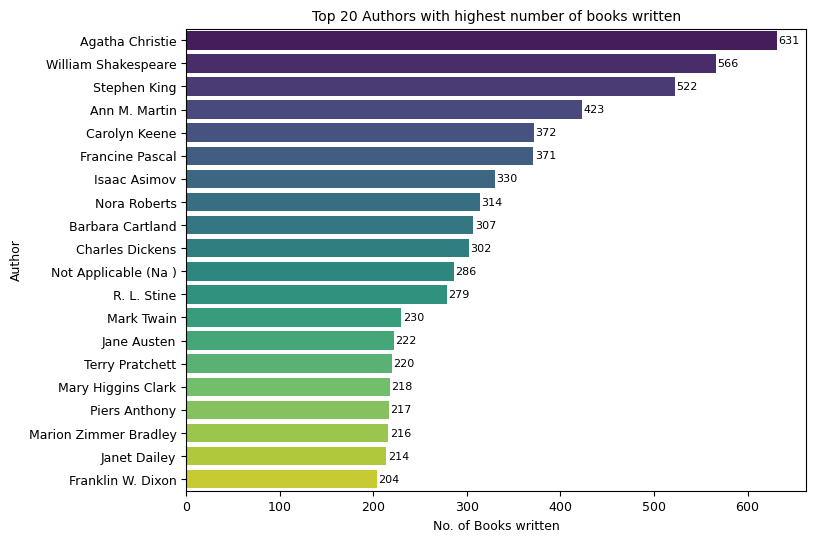

In [51]:
plt.figure(figsize=(8,6))
ax = sns.countplot(y="author", palette='viridis', data=books , order=books['author'].value_counts().index[0:20])
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=1)
    
plt.title("Top 20 Authors with highest number of books written", size=10)
plt.xlabel('No. of Books written', size=9)
plt.ylabel('Author', size=9)
plt.xticks(size=9)
plt.yticks(size=9)
plt.show()

- Agatha Christie authored the highest number of books, with 631 titles, followed by William Shakespeare, who authored 566 books.
- The top three most prolific authors are Agatha Christie (632 titles), William Shakespeare (566 titles), and Stephen King (423 titles). Each of the authors has written more than 500 books.
- The difference in books authored between the most prolific author and the twentieth-ranked author is 436 books.
- The middle tier of the top 20 authors includes Carolyn Keene, Francine Pascal, Isaac Asimov, Nora Roberts, Barbara Cartland, and Charles Dickens. These authors have written between 300 and 400 books.
- The lower end of the top 20 ranking comprises Roald Dahl, Franklin W. Dixon, Janet Dailey, Marion Zimmer Bradley, Piers Anthony, Mary Higgins Clark, Terry Pratchett, Jane Austen. The number of books authored by these writers ranges from 200 to 300 books.

#### *Publishers with highest number of books published*

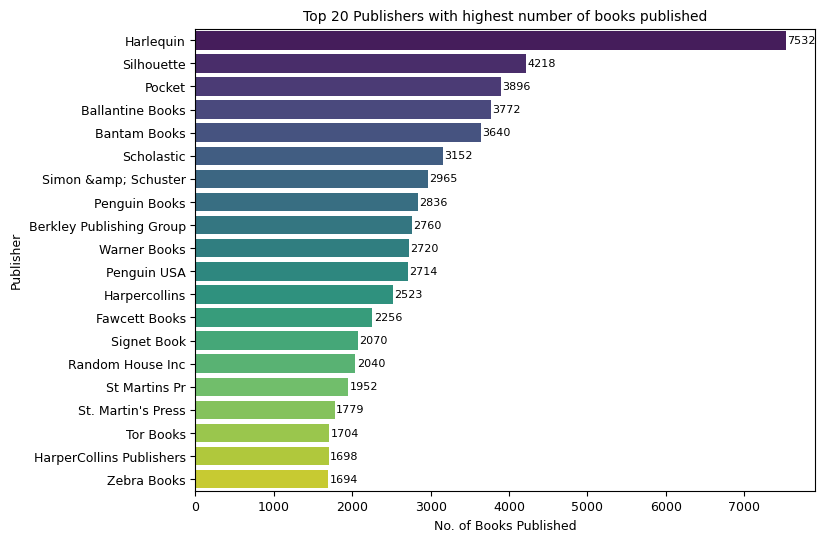

In [52]:
plt.figure(figsize=(8,6))
ax = sns.countplot(y="publisher",palette = 'viridis', data=books, order=books['publisher'].value_counts().index[0:20])
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=1)
plt.title("Top 20 Publishers with highest number of books published", size=10)
plt.xlabel('No. of Books Published', size=9)
plt.ylabel('Publisher', size=9)
plt.xticks(size=9)
plt.yticks(size=9)
plt.show()

- Harlequin published the highest number of books, with 7532 titles, significantly outperforming all other publishers in the ranking.
- The top three publishers are Harlequin (7532 books), Silhouette (4218 books), and Pocket (3896 books). Harlequin is the only publisher with more than 7000 published books, while the other two have published close to or above 4000 books.
- The total output of the top five publishers (Harlequin, Silhouette, Pocket, Ballantine Books, and Bantam Books) exceeds 23000 books, contributing to 40% of the total books published (57921 books) by top 20 publishers.
- The difference between the highest-ranked publisher and the twentieth-ranked publisher is 5838 books (7532 minus 1694).
- The upper tier of top 20 publishers includes Ballantine Books, Bantam Books, Scholastic, Simon & Schuster, Penguin Books, Berkley Publishing Group, Warner Books, and Penguin USA. These publishers have published between 2700 and 3800 books.
- The middle tier of top 20 publishers comprises HarperCollins, Fawcett Books, Signet Book, Random House Inc, and St. Martin's Press, with publication counts ranging from approximately 1900 to 2500 books.
- The lower end of the top 20 ranking includes Tor Books, HarperCollins Publishers, and Zebra Books, each publishing around 1700 books.


#### *Books with highest number of ratings*

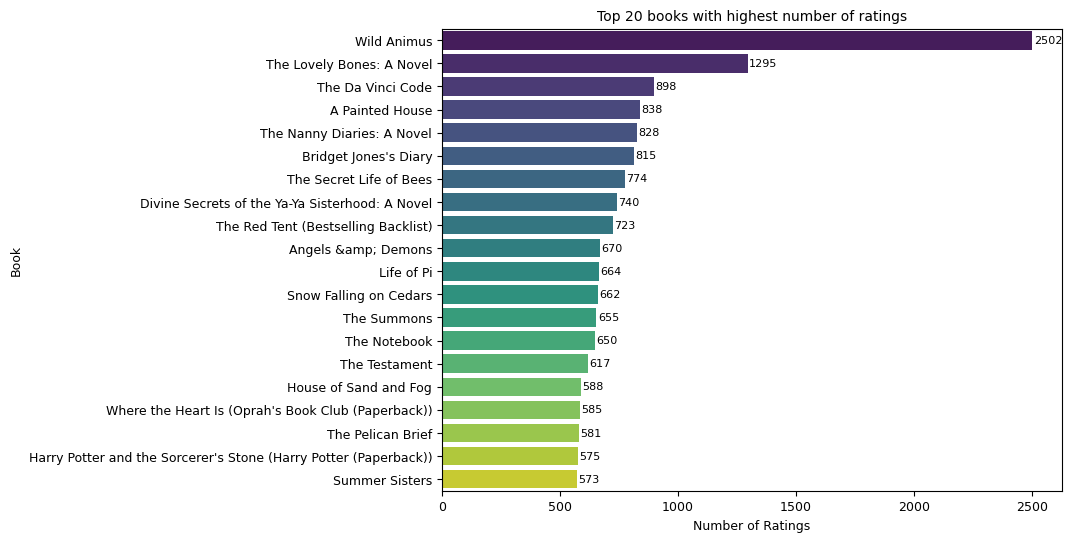

In [53]:
plt.figure(figsize=(8,6))
popular_books_n_ratings = books_content.sort_values(by=['num_ratings'], ascending=False)[['isbn','title','author','year','publisher','image_m','num_ratings']].reset_index().iloc[:,1:]
ax = sns.barplot(data=popular_books_n_ratings.head(20), x="num_ratings", y="title", palette='viridis')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=1)
plt.title("Top 20 books with highest number of ratings",size=10)
plt.xlabel('Number of Ratings', size=9)
plt.ylabel('Book', size=9)
plt.xticks(size=9)
plt.yticks(size=9)
plt.show()

- Wild Animus received the highest number of ratings with 2502 ratings, followed by The Lovely Bones: A Novel, which received 1295 ratings.
- The top three books with the highest number of ratings are Wild Animus, The Lovely Bones: A Novel, and The Da Vinci Code. The reader rating for the books ranges from cllose to 900 to 2500 ratings.
- The middle tier of the top 20 books includes The Secret Life of Bees, Divine Secrets of the Ya-Ya Sisterhood , The Red Tent, Angels & Demons , Life of Pi, and Snow Falling on Cedars. These books received approximately 650 to 800 ratings.
- The lower end of the top 20 ranking comprises The Notebook, The Testament, House of Sand and Fog, Where the Heart Is, The Pelican Brief, Harry Potter and the Sorcerer's Stone, and Summer Sisters. The number of ratings for these books ranges from approximately 570 to 650 ratings.


#### *Countries with highest number of readers*

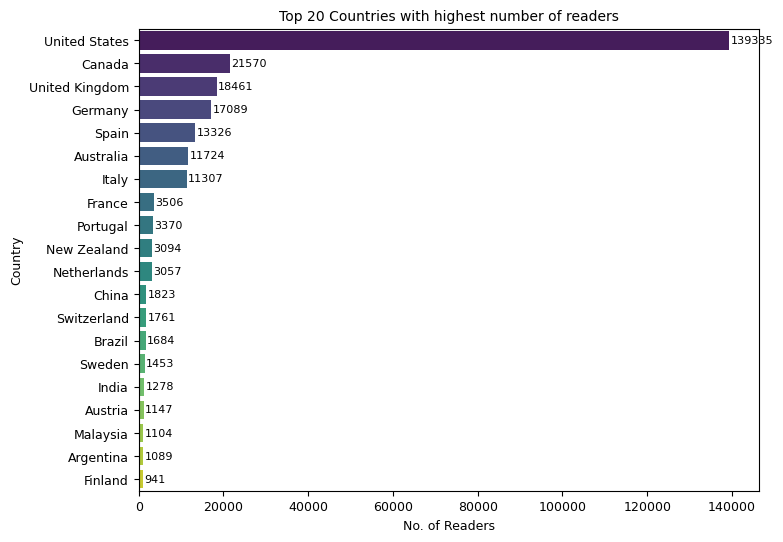

In [54]:
plt.figure(figsize=(8,6))
ax = sns.countplot(y="country",palette = 'viridis', data=users, order=users['country'].value_counts().index[0:20])
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=1)
plt.title("Top 20 Countries with highest number of readers", size=10)
plt.xlabel('No. of Readers', size=9)
plt.ylabel('Country', size=9)
plt.xticks(size=9)
plt.yticks(size=9)
plt.show()

- The United States has the highest number of readers with 139335 readers, exceeding other countries. It is followed by Canada, which has 21570 readers.
- The top three countries with the highest number of readers are United States (139335 readers), Canada (21570 readers), and United Kingdom (18461 readers). The United States dominates the ranking, with more than six times the number of readers recorded in Canada.
- The difference between the highest-ranked country (United States, 139335 readers) and the twentieth-ranked country (Finland, 941 readers) is 138394 readers.
- The upper tier of the ranking includes Germany, Spain, Australia , and Italy. These countries each have between 11000 and 18000 readers.
- The middle tier comprises France, Portugal, New Zealand, and Netherlands. These countries have readership numbers ranging from 3000 to 4000. 
- The lower end of the top 20 ranking includes China, Switzerland, Brazil, Sweden, India, Austria, Malaysia, Argentina, and Finland. These countries each have fewer than 2000 readers.

#### *Distribution plot of book ratings*

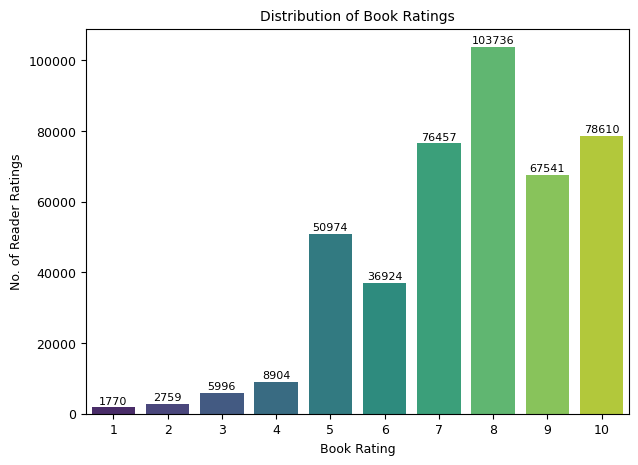

In [55]:
plt.figure(figsize=(7,5))
rate_fil = ratings[ratings['ratings'] != 0]
ax = sns.countplot(x="ratings", palette='viridis', data=rate_fil)
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=1)
plt.title("Distribution of Book Ratings", size=10)
plt.xlabel("Book Rating", size=9)
plt.ylabel("No. of Reader Ratings", size=9)
plt.xticks(size=9)
plt.yticks(size=9)
plt.show()

- The rating score of 8 has the highest frequency, with 103736 ratings, followed by rating 10, which received 78610 ratings.
- Ratings 7 to 10 account for the majority of all ratings, with each receiving more than 65000 ratings. The combined ratings on a scale of 7 to 10 are 326344, contributing to 75% of the total share of the ratings. 
- The median range of ratings includes 5 and 6. These ratings represent moderate to high reader satisfaction and received between 35000 and 50000 reader ratings.
- Low Ratings of 3 to 4 have a lower frequency, reader ratings in the range of 5000 to 10000. 
- Extremely Low ratings of 1 to 2 have frequency fewer than 3000.
- The distribution is negatively skewed (left-skewed), with ratings concentrated toward the higher end of the scale (7 to 10).

#### *Distribution plot of reader age*

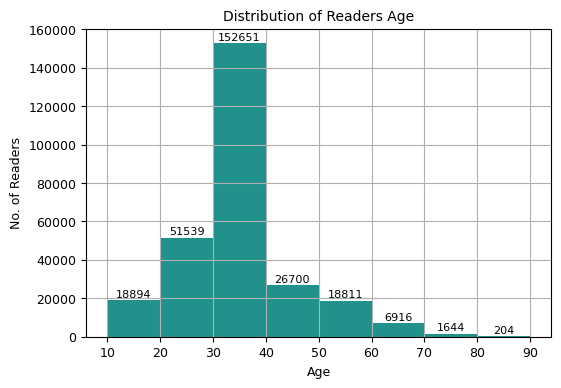

In [56]:
plt.figure(figsize=(6,4))
ax = users.age.hist(bins=[10*i for i in range(1, 10)], color='#21918C')   
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=1)
plt.title('Distribution of Readers Age', size=10)
plt.xlabel('Age', size=9)
plt.ylabel('No. of Readers',size=9)
plt.xticks(size=9)
plt.yticks(size=9)
plt.show()

- The 30-39 years age group alone contributes approximately 55% (152651 readers) of the total readership (277359 readers).
- The most represented age group is 30-39 years with the highest number of 152651 readers, followed by 20-29 years age group, which has 51539 readers. The avid readers are concentrated among individuals aged 20 to 49 years, whose combined total is 204190 readers, accounting for approximately 73% of all readers.
- The moderate reader ages includes the 10-19 years, 40-49 years, and 50-59 years age groups. These groups have readership counts ranging from approximately 18000 to 27000 readers.
- The least represented age group is 60-89 years, with readership less than 7000 indicating very limited participation from the oldest readers.
- The distribution is positively skewed (right-skewed), with readership concentrated among younger and middle-aged adults and gradually decreasing as age increases beyond 40 years.

#### Year-wise Distribution of Published Books

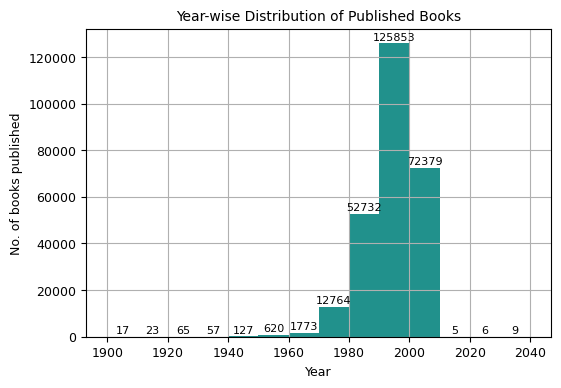

In [57]:
plt.figure(figsize=(6,4))
ax = books.year.hist(bins=list(range(1900,2050,10)),color='#21918C')   
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=1)
plt.title('Year-wise Distribution of Published Books', size=10)
plt.xlabel('Year', size=9)
plt.ylabel('No. of books published',size=9)
plt.xticks(size=9)
plt.yticks(size=9)
plt.show()

- The 1990-1999 decade contributes the largest share of published books, with 125853 books, accounting for approximately 47% of all books published (266430 books). This decade represents the peak period of book publication.
- The most productive publication period is 1980-1989 (52732 books), followed by 1990-1999 (125853 books) and 2000-2009 (72379 books) and combined books published from the decades 1980-2009, contribute to 250964 books, or approximately 94% of all published books.
- The peak publication period of 1980-2009 began its momentum during the decade of 1970-1979 with 12764 books published. This decade marks the beginning of a substantial rise in publication volume.
- The slow phase of the publication periods are the decades before 1970 and after 2010, where the number of published books is generally below 2,000 books per decade.
- The distribution is negatively skewed (left-skewed), with publications heavily concentrated in the more recent decades, particularly from 1980 to 2009, while earlier decades contribute only a small fraction of the total publications.

##  Recommendation System

In [58]:
books_with_rating_fil.head(2)

,user_id,isbn,ratings,age,age_group,country,title,author,year,publisher,image_s,image_m,image_l,num_ratings,avg_ratings,weighted_rating
0,277427,002542730X,10,48.0,Middle aged adults,United States,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,175,3.434286,3.741818
1,277427,0060177721,0,48.0,Middle aged adults,United States,Finding Moon,Tony Hillerman,1995,Harpercollins,http://images.amazon.com/images/P/0060177721.0...,http://images.amazon.com/images/P/0060177721.0...,http://images.amazon.com/images/P/0060177721.0...,68,3.220588,3.851190


### *Simple Recommendation Engine*

Simple recommendation engine works by filtering the top n number of books based on the number of ratings and weighted average of ratings. The top n books based on the number of ratings and weighted average of ratings for various categories such a popularity, country , author,  publisher, publication year, and reader age group.

### Popularity based recommendation

In [59]:
top_n = eval(input())
print(top_n)

20


#### Based on number of ratings

In [60]:
## popular books based on number of ratings
popular_books_n_ratings = books_content.sort_values(by=['num_ratings'], ascending=False)[['isbn','title','author','year','publisher','image_m','num_ratings']].reset_index().iloc[:,1:]
print(popular_books_n_ratings.shape)
display(popular_books_n_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_n_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_n_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))


(2430, 7)


,isbn,title,author,year,publisher,image_m,num_ratings
0,0971880107,Wild Animus,Rich Shapero,2004,Too Far,http://images.amazon.com/images/P/0971880107.0...,2502


Wild Animus(2004) Rich Shapero,The Lovely Bones: A Novel(2002) Alice Sebold,The Da Vinci Code(2003) Dan Brown,A Painted House(2001) JOHN GRISHAM,The Nanny Diaries: A Novel(2002) Emma McLaughlin
Bridget Jones's Diary(1999) Helen Fielding,The Secret Life of Bees(2003) Sue Monk Kidd,Divine Secrets of the Ya-Ya Sisterhood: A Novel(1997) Rebecca Wells,The Red Tent (Bestselling Backlist)(1998) Anita Diamant,Angels & Demons(2001) Dan Brown
Life of Pi(2003) Yann Martel,Snow Falling on Cedars(1995) David Guterson,The Summons(2002) John Grisham,The Notebook(1996) Nicholas Sparks,The Testament(1999) John Grisham
House of Sand and Fog(2000) Andre Dubus III,Where the Heart Is (Oprah's Book Club (Paperback))(1998) Billie Letts,The Pelican Brief(1993) John Grisham,Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback))(1999) J. K. Rowling,Summer Sisters(1999) Judy Blume


#### Based on weighted average of ratings

In [61]:
## popular books based on weighted average of ratings
popular_books_wt_ratings = books_content.sort_values(by=['weighted_rating'], ascending=False)[['isbn', 'title','author','year','publisher','image_m','weighted_rating']].reset_index().iloc[:,1:]
print(popular_books_wt_ratings.shape)
display(popular_books_wt_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_wt_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_wt_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

(2430, 7)


,isbn,title,author,year,publisher,image_m,weighted_rating
0,1844262553,Free,Paul Vincent,2003,Upfront Publishing,http://images.amazon.com/images/P/1844262553.0...,5.621795


Free(2003) Paul Vincent,Harry Potter and the Prisoner of Azkaban (Book 3)(2001) J. K. Rowling,Harry Potter and the Goblet of Fire (Book 4)(2000) J. K. Rowling,Harry Potter and the Sorcerer's Stone (Book 1)(2001) J. K. Rowling,Harry Potter and the Order of the Phoenix (Book 5)(2003) J. K. Rowling
The Little Prince(1968) Antoine de Saint-ExupÃ©ry,Ender's Game (Ender Wiggins Saga (Paperback))(1994) Orson Scott Card,Harry Potter and the Chamber of Secrets (Book 2)(2000) J. K. Rowling,Griffin & Sabine: An Extraordinary Correspondence(1991) Nick Bantock,The Stand (The Complete and Uncut Edition)(1990) Stephen King
The Hobbit(1938) J. R. R. Tolkien,The Hobbit : The Enchanting Prelude to The Lord of the Rings(1986) J.R.R. TOLKIEN,"The Fellowship of the Ring (The Lord of the Rings, Part 1)(1999) J. R. R. Tolkien",Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback))(1999) J. K. Rowling,The Cat in the Hat(1957) Dr. Seuss
The Perks of Being a Wallflower(1999) Stephen Chbosky,"The Two Towers (The Lord of the Rings, Part 2)(1999) J. R. R. Tolkien",Jitterbug Perfume(1985) Tom Robbins,"Rich Dad, Poor Dad: What the Rich Teach Their Kids About Money--That the Poor and Middle Class Do Not!(2000) Robert T. Kiyosaki",The Lord of the Rings (Movie Art Cover)(2001) J.R.R. Tolkien


#### export

In [ ]:
## export
with pd.ExcelWriter(r'.\output\popularity based recommendations\popular_book_recommendations.xlsx', engine='openpyxl') as writer:
    popular_books_n_ratings.head(top_n).to_excel(writer, sheet_name='num_ratings', index=False)
    popular_books_wt_ratings.head(top_n).to_excel(writer, sheet_name='weighted_rating', index=False)

### Country based recommendation

In [62]:
country_dropdown = Dropdown(options= sorted(list(books_content['country'].dropna().unique())),description='Country:')
display(country_dropdown)

top_n = eval(input())
print(top_n)

Dropdown(description='Country:', options=('Australia', 'Canada', 'France', 'Malaysia', 'Netherlands', 'New Zea…

20


#### Based on number of ratings

In [64]:
country = country_dropdown.value
print(country)

## popular books based on number of ratings
popular_books_n_ratings = books_content[books_content['country'] == country].sort_values(by=['num_ratings'], ascending=False)[['title','author','year','publisher','image_m','num_ratings']].reset_index().iloc[:,1:]
print(popular_books_n_ratings.shape)
display(popular_books_n_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_n_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_n_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

United States
(1840, 6)


,title,author,year,publisher,image_m,num_ratings
0,Wild Animus,Rich Shapero,2004,Too Far,http://images.amazon.com/images/P/0971880107.0...,2502


Wild Animus(2004) Rich Shapero,The Lovely Bones: A Novel(2002) Alice Sebold,The Da Vinci Code(2003) Dan Brown,A Painted House(2001) JOHN GRISHAM,The Nanny Diaries: A Novel(2002) Emma McLaughlin
Bridget Jones's Diary(1999) Helen Fielding,The Secret Life of Bees(2003) Sue Monk Kidd,Divine Secrets of the Ya-Ya Sisterhood: A Novel(1997) Rebecca Wells,Angels & Demons(2001) Dan Brown,Life of Pi(2003) Yann Martel
Snow Falling on Cedars(1995) David Guterson,The Summons(2002) John Grisham,The Notebook(1996) Nicholas Sparks,House of Sand and Fog(2000) Andre Dubus III,Where the Heart Is (Oprah's Book Club (Paperback))(1998) Billie Letts
The Pelican Brief(1993) John Grisham,Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback))(1999) J. K. Rowling,Summer Sisters(1999) Judy Blume,The Girls' Guide to Hunting and Fishing(2000) Melissa Bank,The Firm(1992) John Grisham


#### Based on weighted average of ratings

In [65]:
country = country_dropdown.value
print(country)

## popular books based on weighted average of ratings
popular_books_wt_ratings = books_content[books_content['country'] == country].sort_values(by=['weighted_rating'], ascending=False)[['title','author','year','publisher','image_m','weighted_rating']].reset_index().iloc[:,1:]
print(popular_books_wt_ratings.shape)
display(popular_books_wt_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_wt_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_wt_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

United States
(1840, 6)


,title,author,year,publisher,image_m,weighted_rating
0,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,2001,Scholastic,http://images.amazon.com/images/P/0439136369.0...,5.554924


Harry Potter and the Prisoner of Azkaban (Book 3)(2001) J. K. Rowling,Harry Potter and the Goblet of Fire (Book 4)(2000) J. K. Rowling,Harry Potter and the Sorcerer's Stone (Book 1)(2001) J. K. Rowling,Harry Potter and the Order of the Phoenix (Book 5)(2003) J. K. Rowling,The Little Prince(1968) Antoine de Saint-ExupÃ©ry
Ender's Game (Ender Wiggins Saga (Paperback))(1994) Orson Scott Card,Harry Potter and the Chamber of Secrets (Book 2)(2000) J. K. Rowling,Griffin & Sabine: An Extraordinary Correspondence(1991) Nick Bantock,The Stand (The Complete and Uncut Edition)(1990) Stephen King,The Hobbit(1938) J. R. R. Tolkien
The Hobbit : The Enchanting Prelude to The Lord of the Rings(1986) J.R.R. TOLKIEN,"The Fellowship of the Ring (The Lord of the Rings, Part 1)(1999) J. R. R. Tolkien",Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback))(1999) J. K. Rowling,The Cat in the Hat(1957) Dr. Seuss,The Perks of Being a Wallflower(1999) Stephen Chbosky
"The Two Towers (The Lord of the Rings, Part 2)(1999) J. R. R. Tolkien",Jitterbug Perfume(1985) Tom Robbins,"Rich Dad, Poor Dad: What the Rich Teach Their Kids About Money--That the Poor and Middle Class Do Not!(2000) Robert T. Kiyosaki",The Lord of the Rings (Movie Art Cover)(2001) J.R.R. Tolkien,The Giver (21st Century Reference)(1994) LOIS LOWRY


#### export

In [ ]:
## export
with pd.ExcelWriter(rf'.\output\country based recommendations\{country}_popular_book_recommendations.xlsx', engine='openpyxl') as writer:
    popular_books_n_ratings.head(top_n).to_excel(writer, sheet_name='num_ratings', index=False)
    popular_books_wt_ratings.head(top_n).to_excel(writer, sheet_name='weighted_rating', index=False)

### Author based recommendation

In [66]:
author_dropdown = Dropdown(options=sorted(list(books_content['author'].unique())), description='Author:')
display(author_dropdown)

top_n = eval(input())
print(top_n)

Dropdown(description='Author:', options=('A. Manette Ansay', 'A.S. BYATT', 'ALBERT CAMUS', 'ALEX HALEY', 'ALEX…

20


#### Based on number of ratings

In [70]:
author = author_dropdown.value
print(author)

## popular books based on number of ratings
popular_books_n_ratings = books_content[books_content['author'] == author].sort_values(by=['num_ratings'], ascending=False)[['title','author','year','publisher','image_m','num_ratings']].reset_index().iloc[:,1:]
print(popular_books_n_ratings.shape)
display(popular_books_n_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_n_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_n_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

Nora Roberts
(60, 6)


,title,author,year,publisher,image_m,num_ratings
0,Dance upon the Air (Three Sisters Island Trilogy),Nora Roberts,2003,Jove Books,http://images.amazon.com/images/P/0515131229.0...,258


Dance upon the Air (Three Sisters Island Trilogy)(2003) Nora Roberts,Face the Fire (Three Sisters Island Trilogy)(2002) Nora Roberts,The Villa(2001) Nora Roberts,Carolina Moon(2001) Nora Roberts,Heaven and Earth (Three Sisters Island Trilogy)(2003) Nora Roberts
Three Fates(2002) Nora Roberts,Midnight Bayou(2001) Nora Roberts,Jewels of the Sun (Irish Trilogy)(2004) Nora Roberts,Heart of the Sea (Irish Trilogy)(2000) Nora Roberts,Tears of the Moon (Irish Trilogy)(2000) Nora Roberts
Sanctuary(1997) Nora Roberts,River's End(2003) Nora Roberts,The Reef(1999) Nora Roberts,Key of Light (Key Trilogy (Paperback))(2003) Nora Roberts,Key of Light(2003) Nora Roberts
"Truly, Madly Manhattan(2003) Nora Roberts",Summer Pleasures(2002) Nora Roberts,Birthright(2004) Nora Roberts,Engaging The Enemy(2003) Nora Roberts,"Key of Valor (Roberts, Nora. Key Trilogy, 3.)(2003) Nora Roberts"


#### Based on weighted average of ratings

In [71]:
author = author_dropdown.value
print(author)

## popular books based on weighted average of ratings
popular_books_wt_ratings = books_content[books_content['author'] == author].sort_values(by=['weighted_rating'], ascending=False)[['title','author','year','publisher','image_m','weighted_rating']].reset_index().iloc[:,1:]
print(popular_books_wt_ratings.shape)
display(popular_books_wt_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_wt_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_wt_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

Nora Roberts
(60, 6)


,title,author,year,publisher,image_m,weighted_rating
0,Chesapeake Blue (Quinn Brothers (Hardcover)),Nora Roberts,2002,Putnam Publishing Group,http://images.amazon.com/images/P/0399149392.0...,4.071429


Chesapeake Blue (Quinn Brothers (Hardcover))(2002) Nora Roberts,"Key of Valor (Roberts, Nora. Key Trilogy, 3.)(2003) Nora Roberts",Born in Fire(1994) Nora Roberts,Key of Knowledge (Key Trilogy (Paperback))(2003) Nora Roberts,Born in Shame(1996) Nora Roberts
"Night Shield (Intimate Moments, 1027)(2000) Nora Roberts",Birthright(2004) Nora Roberts,Honest Illusions(1995) Nora Roberts,Private Scandals(1994) Nora Roberts,Less Of A Stranger (Silhouette Single Title)(2003) Nora Roberts
Three Fates(2002) Nora Roberts,Brazen Virtue(1996) Nora Roberts,Born in Ice(1996) Nora Roberts,True Betrayals(1996) Nora Roberts,Lawless(2003) Nora Roberts
Midnight Bayou(2001) Nora Roberts,Portrait in Death(2003) Nora Roberts,Dance upon the Air (Three Sisters Island Trilogy)(2003) Nora Roberts,Considering Kate (The Stanislaskis) (Silhouette Special Edition)(2001) Nora Roberts,The Macgregors: Alan - Grant (The Macgregors)(1999) Nora Roberts


#### export

In [ ]:
## export
with pd.ExcelWriter(rf'.\output\author based recommendations\{author}_popular_book_recommendations.xlsx', engine='openpyxl') as writer:
    popular_books_n_ratings.head(top_n).to_excel(writer, sheet_name='num_ratings', index=False)
    popular_books_wt_ratings.head(top_n).to_excel(writer, sheet_name='weighted_rating', index=False)

### Publisher based recommendation

In [72]:
publisher_dropdown = Dropdown(options=sorted(list(books_content['publisher'].unique())), description='Publisher:')
display(publisher_dropdown)

top_n = eval(input())
print(top_n)

Dropdown(description='Publisher:', options=('ACE Charter', 'Ace Books', 'Aladdin', 'Aladdin Library', 'Alfred …

20


#### Based on number of ratings

In [73]:
publisher = publisher_dropdown.value
print(publisher)

## popular books based on number of ratings
popular_books_n_ratings = books_content[books_content['publisher'] == publisher].sort_values(by=['num_ratings'], ascending=False)[['title','author','year','publisher','image_m','num_ratings']].reset_index().iloc[:,1:]
print(popular_books_n_ratings.shape)
display(popular_books_n_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_n_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_n_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

Berkley Publishing Group
(140, 6)


,title,author,year,publisher,image_m,num_ratings
0,Black Notice,Patricia Daniels Cornwell,2000,Berkley Publishing Group,http://images.amazon.com/images/P/0425175405.0...,360


Black Notice(2000) Patricia Daniels Cornwell,Isle of Dogs(2002) Patricia Cornwell,Cause of Death(1997) Patricia Daniels Cornwell,Point of Origin(1999) Patricia Daniels Cornwell,Lightning(1996) Dean R. Koontz
Hornet's Nest(1998) Patricia Daniels Cornwell,The Hunt for Red October(1990) Tom Clancy,Breathing Lessons(1998) Anne Tyler,Southern Cross(1999) Patricia Daniels Cornwell,From Potter's Field(1996) Patricia Daniels Cornwell
Sophie's World: A Novel About the History of Philosophy(1996) Jostein Gaarder,Here on Earth(1998) Alice Hoffman,The Talisman(1991) Stephen King,The Body Farm(1995) Patricia Daniels Cornwell,Big Trouble(2001) Dave Barry
The Rapture of Canaan(1997) Sheri Reynolds,Chosen Prey(2004) John Sandford,Red Storm Rising(1997) Tom Clancy,Watchers(1996) Dean R. Koontz,Rainbow Six(2004) Tom Clancy


#### Based on weighted average of ratings

In [74]:
publisher = publisher_dropdown.value
print(publisher)

## popular books based on weighted average of ratings
popular_books_wt_ratings = books_content[books_content['publisher'] == publisher].sort_values(by=['weighted_rating'], ascending=False)[['title','author','year','publisher','image_m','weighted_rating']].reset_index().iloc[:,1:]
print(popular_books_wt_ratings.shape)
display(popular_books_wt_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_wt_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_wt_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

Berkley Publishing Group
(140, 6)


,title,author,year,publisher,image_m,weighted_rating
0,And Then There Were None,Agatha Christie,1995,Berkley Publishing Group,http://images.amazon.com/images/P/0425129586.0...,4.293194


And Then There Were None(1995) Agatha Christie,Hocus Pocus(1991) Kurt Vonnegut,Replay(1988) Ken Grimwood,Deep South(2001) Nevada Barr,Pot Shot(2002) Robert B. Parker
It's Not About the Bike: My Journey Back to Life(2001) Lance Armstrong,Glory in Death(2004) J. D. Robb,Hunting Season (Anna Pigeon Novels (Paperback))(2003) Nevada Barr,Tricky Business(2003) Dave Barry,The Face of Fear(1996) Dean R. Koontz
Judgment in Death(2004) J. D. Robb,Family Honor(2000) Robert B. Parker,Reunion in Death(2002) J. D. Robb,Fire Ice: A Novel from the Numa Files (Kurt Austin Adventures (Paperback))(2003) Clive Cussler,A Small Death in Lisbon(2002) Robert Wilson
Atlantis Found(2001) Clive Cussler,The Talisman(1991) Stephen King,Here on Earth (Oprah's Book Club)(1999) Alice Hoffman,The Voice of the Night(1996) Dean R. Koontz,Dune(1984) Frank Herbert


#### export

In [ ]:
## export
with pd.ExcelWriter(rf'.\output\publisher based recommendations\{publisher}_popular_book_recommendations.xlsx', engine='openpyxl') as writer:
    popular_books_n_ratings.head(top_n).to_excel(writer, sheet_name='num_ratings', index=False)
    popular_books_wt_ratings.head(top_n).to_excel(writer, sheet_name='weighted_rating', index=False)

### Publication Year based recommendation

In [75]:
year_dropdown = Dropdown(options=sorted(list(books_content['year'].unique())), description='Year:')
display(year_dropdown)

top_n = eval(input())
print(top_n)

Dropdown(description='Year:', options=(np.int64(1938), np.int64(1953), np.int64(1954), np.int64(1957), np.int6…

20


#### Based on number of ratings

In [76]:
year = year_dropdown.value
print(year)

## popular books based on number of ratings
popular_books_n_ratings = books_content[books_content['year'] == year].sort_values(by=['num_ratings'], ascending=False)[['title','author','year','publisher','image_m','num_ratings']].reset_index().iloc[:,1:]
print(popular_books_n_ratings.shape)
display(popular_books_n_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_n_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_n_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

1991
(65, 6)


,title,author,year,publisher,image_m,num_ratings
0,The Catcher in the Rye,J.D. Salinger,1991,"Little, Brown",http://images.amazon.com/images/P/0316769487.0...,449


The Catcher in the Rye(1991) J.D. Salinger,Silence of the Lambs(1991) Thomas Harris,Circle of Friends(1991) Maeve Binchy,The Talisman(1991) Stephen King,The Mummy or Ramses the Damned(1991) Anne Rice
G Is for Gumshoe (Kinsey Millhone Mysteries (Paperback))(1991) Sue Grafton,Slaughterhouse Five or the Children's Crusade: A Duty Dance With Death(1991) Kurt Vonnegut,Animal Dreams(1991) Barbara Kingsolver,The Burden of Proof(1991) Scott Turow,A Year in Provence(1991) Peter Mayle
Possession : A Romance(1991) A.S. BYATT,The Plains of Passage (Earth's Children (Paperback))(1991) JEAN M. AUEL,The Stand: Complete and Uncut(1991) Stephen King,September(1991) Rosamunde Pilcher,The House on Mango Street (Vintage Contemporaries)(1991) SANDRA CISNEROS
On the Road(1991) Jack Kerouac,No Greater Love(1991) Danielle Steel,The Bourne Ultimatum(1991) Robert Ludlum,Outbreak(1991) Robin Cook,The Anastasia Syndrome(1991) Mary Higgins Clark


#### Based on weighted average of ratings

In [77]:
year = year_dropdown.value
print(year)

## popular books based on weighted average of ratings
popular_books_wt_ratings = books_content[books_content['year'] == year].sort_values(by=['weighted_rating'], ascending=False)[['title','author','year','publisher','image_m','weighted_rating']].reset_index().iloc[:,1:]
print(popular_books_wt_ratings.shape)
display(popular_books_wt_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_wt_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_wt_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))



1991
(65, 6)


,title,author,year,publisher,image_m,weighted_rating
0,Griffin &amp; Sabine: An Extraordinary Corresp...,Nick Bantock,1991,Chronicle Books,http://images.amazon.com/images/P/0877017883.0...,5.017442


Griffin & Sabine: An Extraordinary Correspondence(1991) Nick Bantock,The Catcher in the Rye(1991) J.D. Salinger,The Stand: Complete and Uncut(1991) Stephen King,Gift from the Sea(1991) Anne Morrow Lindbergh,Nine Stories(1991) J.D. Salinger
Needful Things: The Last Castle Rock Story(1991) Stephen King,A Natural History of the Senses(1991) Diane Ackerman,Foundation (Foundation Novels (Paperback))(1991) ISAAC ASIMOV,On the Road(1991) Jack Kerouac,Slaughterhouse Five or the Children's Crusade: A Duty Dance With Death(1991) Kurt Vonnegut
Hocus Pocus(1991) Kurt Vonnegut,SKINNY LEGS AND ALL(1991) TOM ROBBINS,A Year in Provence(1991) Peter Mayle,Silence of the Lambs(1991) Thomas Harris,White Noise (Contemporary American Fiction)(1991) Don DeLillo
Long Dark Tea Time of the Soul(1991) Douglas Adams,The House on Mango Street (Vintage Contemporaries)(1991) SANDRA CISNEROS,Dragonflight (Dragonriders of Pern Trilogy (Paperback))(1991) Anne McCaffrey,Life's Little Instruction Book (Life's Little Instruction Books (Paperback))(1991) H. Jackson Brown,Moreta: Dragonlady of Pern(1991) Anne McCaffrey


#### export

In [ ]:
## export
with pd.ExcelWriter(rf'.\output\year based recommendations\{year}_popular_book_recommendations.xlsx', engine='openpyxl') as writer:
    popular_books_n_ratings.head(top_n).to_excel(writer, sheet_name='num_ratings', index=False)
    popular_books_wt_ratings.head(top_n).to_excel(writer, sheet_name='weighted_rating', index=False)

### Reader Agegroup based recommendation

In [78]:
age_group_dropdown = Dropdown(options=sorted(list(books_content['age_group'].unique())), description='Year:')
display(age_group_dropdown)

top_n = eval(input())
print(top_n)

Dropdown(description='Year:', options=('Elderly', 'Middle aged adults', 'Teens', 'Youth'), value='Elderly')

20


#### Based on number of ratings

In [79]:
age_group = age_group_dropdown.value
print(age_group)

## popular books based on number of ratings
popular_books_n_ratings = books_content[books_content['age_group'] == age_group].sort_values(by=['num_ratings'], ascending=False)[['title','author','year','publisher','image_m','num_ratings']].reset_index().iloc[:,1:]
print(popular_books_n_ratings.shape)
display(popular_books_n_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_n_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_n_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

Youth
(1890, 6)


,title,author,year,publisher,image_m,num_ratings
0,A Painted House,JOHN GRISHAM,2001,Doubleday,http://images.amazon.com/images/P/038550120X.0...,838


A Painted House(2001) JOHN GRISHAM,The Nanny Diaries: A Novel(2002) Emma McLaughlin,Bridget Jones's Diary(1999) Helen Fielding,Divine Secrets of the Ya-Ya Sisterhood: A Novel(1997) Rebecca Wells,The Red Tent (Bestselling Backlist)(1998) Anita Diamant
Angels & Demons(2001) Dan Brown,Snow Falling on Cedars(1995) David Guterson,The Notebook(1996) Nicholas Sparks,The Testament(1999) John Grisham,House of Sand and Fog(2000) Andre Dubus III
Where the Heart Is (Oprah's Book Club (Paperback))(1998) Billie Letts,The Girls' Guide to Hunting and Fishing(2000) Melissa Bank,Summer Sisters(1999) Judy Blume,The Firm(1992) John Grisham,The Pilot's Wife : A Novel(1999) Anita Shreve
The Brethren(2000) John Grisham,The Joy Luck Club(1994) Amy Tan,Timeline(2000) MICHAEL CRICHTON,Girl with a Pearl Earring(2001) Tracy Chevalier,To Kill a Mockingbird(1988) Harper Lee


#### Based on weighted average of ratings

In [80]:
age_group = age_group_dropdown.value
print(age_group)

## popular books based on weighted average of ratings
popular_books_wt_ratings = books_content[books_content['age_group'] == age_group].sort_values(by=['weighted_rating'], ascending=False)[['title','author','year','publisher','image_m','weighted_rating']].reset_index().iloc[:,1:]
print(popular_books_wt_ratings.shape)
display(popular_books_wt_ratings.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(popular_books_wt_ratings.head(top_n)), n_columns):
    html += "<tr>"
    for _, row in popular_books_wt_ratings.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

Youth
(1890, 6)


,title,author,year,publisher,image_m,weighted_rating
0,Free,Paul Vincent,2003,Upfront Publishing,http://images.amazon.com/images/P/1844262553.0...,5.621795


Free(2003) Paul Vincent,Harry Potter and the Goblet of Fire (Book 4)(2000) J. K. Rowling,Harry Potter and the Order of the Phoenix (Book 5)(2003) J. K. Rowling,The Little Prince(1968) Antoine de Saint-ExupÃ©ry,Ender's Game (Ender Wiggins Saga (Paperback))(1994) Orson Scott Card
The Stand (The Complete and Uncut Edition)(1990) Stephen King,The Hobbit(1938) J. R. R. Tolkien,"The Fellowship of the Ring (The Lord of the Rings, Part 1)(1999) J. R. R. Tolkien",The Cat in the Hat(1957) Dr. Seuss,The Perks of Being a Wallflower(1999) Stephen Chbosky
"The Two Towers (The Lord of the Rings, Part 2)(1999) J. R. R. Tolkien",Jitterbug Perfume(1985) Tom Robbins,Fear and Loathing in Las Vegas : A Savage Journey to the Heart of the American Dream(1998) HUNTER S. THOMPSON,Ishmael: An Adventure of the Mind and Spirit(1995) Daniel Quinn,Interpreter of Maladies(1999) Jhumpa Lahiri
To Kill a Mockingbird(1988) Harper Lee,The Vagina Monologues: The V-Day Edition(2000) Eve Ensler,Anne Frank: The Diary of a Young Girl(1993) ANNE FRANK,The Godfather(2004) Mario Puzo,Charlie and the Chocolate Factory(1994) Roald Dahl


#### export

In [ ]:
## export
with pd.ExcelWriter(rf'.\output\age_group based recommendations\{age_group}_popular_book_recommendations.xlsx', engine='openpyxl') as writer:
    popular_books_n_ratings.head(top_n).to_excel(writer, sheet_name='num_ratings', index=False)
    popular_books_wt_ratings.head(top_n).to_excel(writer, sheet_name='weighted_rating', index=False)

### *Advanced Recommendation Engine*

A recommendation system is usually built using 3 techniques which are content-based filtering, collaborative filtering, and hybrid filtering.

**Content-Based Filtering:** Content-based filtering is a recommendation technique that suggests items to users based on the characteristics of items they have liked, viewed, or interacted with in the past based on a similarity score. The similarity score is computed by vectorization of text inputs.

**Collaborative-based Filtering:** Collaborative based filtering is a recommendation technique that suggests items to users based on the characteristics of items they have liked, viewed, or interacted with in the past based on a similarity score. The similarity score is computed for the numerical inputs.

**Hybrid Filtering Method:** It is a combination of content-based and collaborative-filtering methods. The recommendation system is built on a similarity score computed on text and numerical inputs.

<u>**Evaluation metrics**</u>
<br>

**Recall@K**: It gives a measure of how many of the relevant items are present in top K out of all the relevant items, where K is the number of recommendations generated for a user. Recall@K is given by the formula, 
<center>Recall@K = Number of relevant items in Top K / Total Number of relevant items</center>
<!-- <center>Total Number of relevant items</center> -->

**Precision@K**: It gives a measure of out of K items recommended to a user and how many are relevant, where K is the number of recommendations generated for a user. Precision@K is given by the formula, 
<center> Precision@K = Number of relevant items in Top K / K</center>
<center></center>
<!-- <center>K</center> -->

### Book Title based Recommendation

In [82]:
title_dropdown = Dropdown(options=sorted(list(books_with_rating_fil['title'].unique())),description='Title:')
display(title_dropdown)

top_n = eval( input() )
print(top_n)

Dropdown(description='Title:', options=('10 Lb. Penalty', '16 Lighthouse Road', '1984', '1st to Die: A Novel',…

20


#### collaborative filtering

In [543]:
book_pivot = books_with_rating_fil.pivot_table(columns='user_id', index='title', values= 'ratings')
book_pivot.fillna(0, inplace=True)
display(book_pivot.head(1))
print(book_pivot.shape)

pickle.dump(book_pivot,open(r'.\input\transformed\book_pivot.pkl','wb'))  


user_id,254,2276,2766,2977,3363,3757,4017,4385,6242,6251,...,274004,274061,274301,274308,274808,275970,277427,277478,277639,278418
title,,,,,,,,,,,,,,,,,,,,,
10 Lb. Penalty,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


(2430, 895)


##### cosine similarity method

In [83]:
def cosine_ratings_model(ratings_df):
    similarity_scores = cosine_similarity(ratings_df)
    print(similarity_scores.shape)
    pickle.dump(similarity_scores,open(r'.\output\title based recommendations\cosine ratings\similarity_scores.pkl','wb'))  
def recommend(book_name, ratings_df, books_df, top_n, sim_matrix_collab):
    """
    Given a book title, this function returns a list of the top 10 similar books
    based on the collaborative filtering similarity matrix.
    """

    #Find the index of the given book in the pivot table
    index = np.where(ratings_df.index == book_name)[0][0]

    #Retrieve similarity scores for the given book and sort them in descending order and exclude the first result (which is the book itself)
    similar_items = sorted(list(enumerate(sim_matrix_collab[index])), 
                           key=lambda x: x[1], reverse=True)[1:top_n+1]

    #Extract the details of similar books
    recommendations = []
    for i in similar_items:
        book_info = []
        temp_df = books_df[books_df['title'] == ratings_df.index[i[0]]]
  
        book_info.extend(list(temp_df.drop_duplicates('title')['isbn'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['title'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['author'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['year'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['publisher'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['image_m'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['num_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['avg_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['weighted_rating'].values))
        book_info.extend([i[1]])  # Append the similarity score

        recommendations.append(book_info)

    return recommendations

In [ ]:
## computing cosine similarity
cosine_ratings_model(ratings_df=book_pivot)

### loading data files
book_pivot = pd.read_pickle(r'.\input\transformed\book_pivot.pkl')
print(book_pivot.shape)
books_with_rating_fil = pd.read_pickle(r'.\input\transformed\books_with_rating_fil.pkl')
print(books_with_rating_fil.shape)
similarity_scores = pd.read_pickle(r'.\output\title based recommendations\cosine ratings\similarity_scores.pkl')
print(similarity_scores.shape)

## enter book name in input
book_name = title_dropdown.value
print(book_name)

(2430, 895)
(109107, 16)
(2430, 2430)
A Beautiful Mind: The Life of Mathematical Genius and Nobel Laureate John Nash


In [85]:
## book recommendation engine
book_recommendations = recommend(book_name=book_name, ratings_df=book_pivot, books_df=books_with_rating_fil, top_n=top_n, sim_matrix_collab=similarity_scores)
book_recommendations_df = pd.DataFrame(book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])
book_recommendations_df.to_excel(rf'.\output\title based recommendations\cosine ratings\{clean_filename(book_name)} book_recommendations.xlsx', index=False)
display(book_recommendations_df.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(book_recommendations_df), n_columns):
    html += "<tr>"
    for _, row in book_recommendations_df.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

,isbn,title,author,year,publisher,image_m,num_ratings,avg_ratings,weighted_rating,similarity_score
0,0446524131,Something More: Excavating Your Authentic Self,Sarah Ban Breathnach,1998,Warner Books,http://images.amazon.com/images/P/0446524131.0...,50,2.14,3.566667,0.270172


Something More: Excavating Your Authentic Self(1998) Sarah Ban Breathnach,The Odyssey(1999) Robert Fagles,Shoeless Joe(1989) W. P. Kinsella,Four Blondes(2000) Candace Bushnell,The First Man in Rome(1991) Colleen McCullough
AGE OF INNOCENCE (MOVIE TIE-IN)(1993) Edith Wharton,Acts of Malice(2000) Perri O'Shaughnessy,Deception on His Mind(1997) Elizabeth George,The Rule of Four(2004) Ian Caldwell,Lovers(1995) Judith Krantz
In Pursuit of the Proper Sinner(1999) Elizabeth George,Cause Celeb(2002) Helen Fielding,Secret History : A Novel(1996) DONNA TARTT,Plum Island(1998) Nelson DeMille,The Cat Who Went to Heaven(1990) Elizabeth Coatsworth
The Tailor of Panama(1997) John Le Carre,The Tortilla Curtain(1996) T. Coraghessan Boyle,Make the Connection: Ten Steps to a Better Body and a Better Life(1996) Bob Greene,The Bear and the Dragon(2000) Tom Clancy,The Other Boleyn Girl(2002) Philippa Gregory


##### nearest neighbours method

In [86]:
def nn_ratings_model(ratings_df):
    book_sparse = csr_matrix(ratings_df)
    model = NearestNeighbors(metric='cosine', algorithm='brute')
    model.fit(book_sparse)
    pickle.dump(model,open(r'.\output\title based recommendations\nn ratings\model.pkl','wb'))   
def nn_book_recommend(book_name, ratings_df, books_df, top_n, model):
    """
    Given a book title, this function returns a list of the top 10 similar books
    based on the Nearest Neighbors model.
    """

    #Find the index of the given book in the pivot table
    index = np.where(ratings_df.index == book_name)[0][0]

    #Retrieve distances and indices of the nearest neighbors
    distance, suggestion =model.kneighbors(ratings_df.iloc[index,:].values.reshape(1,-1), n_neighbors=top_n+1)
    distance = distance[0][1:]
    suggestion = suggestion[0][1:]

    #Extract the details of similar books
    recommendations = []
    for i in suggestion:
        book_info = []
        temp_df = books_df[books_df['title'] == ratings_df.index[i]]

        book_info.extend(list(temp_df.drop_duplicates('title')['isbn'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['title'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['author'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['year'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['publisher'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['image_m'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['num_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['avg_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['weighted_rating'].values))
        book_info.extend([distance[np.where(suggestion == i)[0][0]]])  # Append the distance score

        recommendations.append(book_info)

    return recommendations        

In [ ]:
## nn model of ratings & save model file
nn_ratings_model(ratings_df=book_pivot)

### loading data files
book_pivot = pd.read_pickle(r'.\input\transformed\book_pivot.pkl')
print(book_pivot.shape)
books_with_rating_fil = pd.read_pickle(r'.\input\transformed\books_with_rating_fil.pkl')
print(books_with_rating_fil.shape)
model = joblib.load(r'.\output\title based recommendations\nn ratings\model.pkl')

## enter book name in input
book_name = title_dropdown.value
print(book_name)

(2430, 895)
(109107, 16)
A Beautiful Mind: The Life of Mathematical Genius and Nobel Laureate John Nash


In [88]:
# book recommendation engine
book_recommendations = nn_book_recommend(book_name=book_name, ratings_df=book_pivot, books_df=books_with_rating_fil, top_n=top_n, model=model)
book_recommendations_df = pd.DataFrame(book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'distance_score'])
book_recommendations_df.to_excel(rf'.\output\title based recommendations\nn ratings\{clean_filename(book_name)} book_recommendations.xlsx',index=False)
display(book_recommendations_df.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(book_recommendations_df), n_columns):
    html += "<tr>"
    for _, row in book_recommendations_df.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

,isbn,title,author,year,publisher,image_m,num_ratings,avg_ratings,weighted_rating,distance_score
0,0446524131,Something More: Excavating Your Authentic Self,Sarah Ban Breathnach,1998,Warner Books,http://images.amazon.com/images/P/0446524131.0...,50,2.14,3.566667,0.729828


Something More: Excavating Your Authentic Self(1998) Sarah Ban Breathnach,The Odyssey(1999) Robert Fagles,Shoeless Joe(1989) W. P. Kinsella,Four Blondes(2000) Candace Bushnell,The First Man in Rome(1991) Colleen McCullough
AGE OF INNOCENCE (MOVIE TIE-IN)(1993) Edith Wharton,Acts of Malice(2000) Perri O'Shaughnessy,Deception on His Mind(1997) Elizabeth George,The Rule of Four(2004) Ian Caldwell,Lovers(1995) Judith Krantz
In Pursuit of the Proper Sinner(1999) Elizabeth George,Cause Celeb(2002) Helen Fielding,Secret History : A Novel(1996) DONNA TARTT,Plum Island(1998) Nelson DeMille,The Cat Who Went to Heaven(1990) Elizabeth Coatsworth
The Tailor of Panama(1997) John Le Carre,The Tortilla Curtain(1996) T. Coraghessan Boyle,Make the Connection: Ten Steps to a Better Body and a Better Life(1996) Bob Greene,The Bear and the Dragon(2000) Tom Clancy,The Other Boleyn Girl(2002) Philippa Gregory


#### content filtering

In [89]:
def cosine_content_model(books_content):
    tfidf = TfidfVectorizer(stop_words='english', max_features=10000)
    tfidf_matrix = tfidf.fit_transform(books_content['content_features'])
    similarity_matrix = cosine_similarity(tfidf_matrix)
    pickle.dump(similarity_matrix,open(r'.\output\title based recommendations\cosine contents\similarity_scores.pkl', 'wb'))
def book_content_recommend(book_name, books_content, top_n, sim_matrix_content):
    """
    Given a book title, this function returns a list of the top 10 similar books
    based on the collaborative filtering similarity matrix.
    """

    #Find the index of the given book in the pivot table
    # index = np.where(ratings_df.index == book_name)[0][0]
    index = books_content[books_content['title'] == book_name].index[0]

    #Retrieve similarity scores for the given book and sort them in descending order and exclude the first result (which is the book itself)
    similar_items = sorted(list(enumerate(sim_matrix_content[index])), 
                           key=lambda x: x[1], reverse=True)[1:top_n+1]

    #Extract the details of similar books
    recommendations = []
    for i in similar_items:
        book_info = []
        temp_df = books_content.iloc[i[0]:i[0]+1,:]

        book_info.extend(list(temp_df.drop_duplicates('title')['isbn'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['title'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['author'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['year'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['publisher'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['image_m'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['num_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['avg_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['weighted_rating'].values))
        book_info.extend([i[1]])  # Append the similarity score

        recommendations.append(book_info)

    return recommendations  

In [ ]:
## loading data files
books_content = pd.read_pickle(r'.\input\transformed\books_content.pkl')

## book recommendation based on cosine similarity of contents & save model
cosine_content_model(books_content=books_content)

## enter book name in input
book_name = title_dropdown.value
print(book_name)

## load similarity scores
similarity_scores = pd.read_pickle(r'.\output\title based recommendations\cosine contents\similarity_scores.pkl')
print(similarity_scores.shape)

A Beautiful Mind: The Life of Mathematical Genius and Nobel Laureate John Nash
(2430, 2430)


In [91]:
## book recommendation engine
book_recommendations = book_content_recommend(book_name=book_name, books_content=books_content, top_n=top_n, sim_matrix_content=similarity_scores)
book_recommendations_df = pd.DataFrame(book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])
book_recommendations_df.to_excel(rf'.\output\title based recommendations\cosine contents\{clean_filename(book_name)} book_recommendations.xlsx',index=False)
display(book_recommendations_df.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(book_recommendations_df), n_columns):
    html += "<tr>"
    for _, row in book_recommendations_df.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

,isbn,title,author,year,publisher,image_m,num_ratings,avg_ratings,weighted_rating,similarity_score
0,0684863472,A Heartbreaking Work Of Staggering Genius : A ...,Dave Eggers,2000,Simon &amp; Schuster,http://images.amazon.com/images/P/0684863472.0...,67,3.104478,3.808383,0.214616


A Heartbreaking Work Of Staggering Genius : A Memoir Based on a True Story(2000) Dave Eggers,On the Street Where You Live : A Novel(2001) Mary Higgins Clark,REMEMBER ME(1994) Mary Higgins Clark,YOU BELONG TO ME(1998) Mary Higgins Clark,EVERYTHING SHE EVER WANTED(1992) Ann Rule
MOONLIGHT BECOMES YOU(1996) Mary Higgins Clark,The Second Time Around : A Novel(2003) Mary Higgins Clark,"Hello, Darkness(2003) Sandra Brown",TIME AND AGAIN(1970) Jack Finney,Messiah(1999) Andrei Codrescu
Deck the Halls(2000) Mary Higgins Clark,Mind Prey(2004) John Sandford,Catch 22(1996) Joseph Heller,Before I Say Good-Bye : A Novel(2000) Mary Higgins Clark,Pay It Forward: A Novel(2000) Catherine Ryan Hyde
Living History(2003) Hillary Rodham Clinton,The Lottery Winner: Alvirah and Willy Stories(1994) Mary Higgins Clark,And Never Let Her Go : Thomas Capano: The Deadly Seducer(1999) Ann Rule,SILENT NIGHT : The Story of the World War I Christmas Truce(1995) Mary Higgins Clark,Mount Vernon Love Story : A Novel of George and Martha Washington(2002) Mary Higgins Clark


#### hybrid filtering

In [92]:
def hybrid_recommender(book_name, ratings_df, books_df, top_n, sim_matrix_collab, books_content, sim_matrix_content, content_wt, collab_wt):
    
    ## collaborative filtering
    collab_book_recommendations = recommend(book_name, ratings_df, books_df, top_n, sim_matrix_collab)
    collab_book_recommendations_df = pd.DataFrame(collab_book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])
    collab_book_recommendations_df['similarity_score']  = collab_book_recommendations_df['similarity_score'] * collab_wt
    # display(collab_book_recommendations_df.head(10))

    ## content filtering
    content_book_recommendations = book_content_recommend(book_name, books_content, top_n, sim_matrix_content)
    content_book_recommendations_df = pd.DataFrame(content_book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])
    content_book_recommendations_df['similarity_score']  = content_book_recommendations_df['similarity_score'] * content_wt
    # display(content_book_recommendations_df.head(10))


    result = pd.merge(collab_book_recommendations_df, content_book_recommendations_df, how='outer', on=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating',]).fillna(0)
    result['similarity_score'] = result['similarity_score_x'] + result['similarity_score_y']
    result.drop(columns=['similarity_score_x', 'similarity_score_y'], inplace=True)
    result = result.sort_values(by=['similarity_score'], ascending=False).reset_index().iloc[:,1:]
    return result

In [203]:
### loading data files
book_pivot = pd.read_pickle(r'.\input\transformed\book_pivot.pkl')
print(book_pivot.shape)
books_content = pd.read_pickle(r'.\input\transformed\books_content.pkl')
print(books_content.shape)
books_with_rating_fil = pd.read_pickle(r'.\input\transformed\books_with_rating_fil.pkl')
print(books_with_rating_fil.shape)
collab_similarity_scores = pd.read_pickle(r'.\output\title based recommendations\cosine ratings\similarity_scores.pkl')
print(collab_similarity_scores.shape)
content_similarity_scores = pd.read_pickle(r'.\output\title based recommendations\cosine contents\similarity_scores.pkl')
print(content_similarity_scores.shape)

## enter book name in input
book_name = title_dropdown.value
print(book_name)

(2430, 895)
(2430, 17)
(109107, 16)
(2430, 2430)
(2430, 2430)
A Beautiful Mind: The Life of Mathematical Genius and Nobel Laureate John Nash


In [202]:
## book recommendation engine
hybrid_book_recommendations_df = hybrid_recommender(book_name=book_name, ratings_df=book_pivot, books_df=books_with_rating_fil, top_n=top_n, sim_matrix_collab=collab_similarity_scores, 
books_content=books_content, sim_matrix_content=content_similarity_scores, content_wt=0.3, collab_wt=0.7)
hybrid_book_recommendations_df.to_excel(rf'.\output\title based recommendations\hybrid\{clean_filename(book_name)} book_recommendations.xlsx',index=False)
display(hybrid_book_recommendations_df.head(1))  

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(book_recommendations_df), n_columns):
    html += "<tr>"
    for _, row in book_recommendations_df.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

,isbn,title,author,year,publisher,image_m,num_ratings,avg_ratings,weighted_rating,similarity_score
0,0446524131,Something More: Excavating Your Authentic Self,Sarah Ban Breathnach,1998,Warner Books,http://images.amazon.com/images/P/0446524131.0...,50,2.14,3.566667,0.18912


A Man in Full(1998) Tom Wolfe,Coming Home(1996) Rosamunde Pilcher,"Assassins: Assignment: Jerusalem, Target: Antichrist (Left Behind No. 6)(2000) Tim Lahaye",Critical Mass(1999) Steven Paul Martini,Big Cherry Holler: A Big Stone Gap Novel (Ballantine Reader's Circle)(2002) Adriana Trigiani
A Beautiful Mind: The Life of Mathematical Genius and Nobel Laureate John Nash(2001) Sylvia Nasar,American Gods(2002) Neil Gaiman,Billy Straight : A Novel(1999) JONATHAN KELLERMAN,Candide (Penguin Classics)(1990) Francois M. Voltaire,A Thin Dark Line (Mysteries & Horror)(1998) TAMI HOAG
A Fine Balance(2001) Rohinton Mistry,All I Really Need to Know(1989) ROBERT FULGHUM,A Monk Swimming : A Memoir(1999) Malachy McCourt,A Time to Kill(1992) JOHN GRISHAM,All Creatures Great and Small(1985) James Herriot
"All the Pretty Horses (The Border Trilogy, Vol 1)(1993) CORMAC MCCARTHY",All Through the Night (Holiday Classics)(1999) Mary Higgins Clark,A Thousand Acres (Ballantine Reader's Circle)(1992) JANE SMILEY,All the Queen's Men(2000) Linda Howard,An Equal Music(2000) Vikram Seth


### Reader based Recommendation

In [95]:
user_dropdown = Dropdown(options=sorted(list(books_with_rating_fil['user_id'].unique())),description='User ID:')
display(user_dropdown)

top_n = eval( input() )
print(top_n)

Dropdown(description='User ID:', options=(np.int64(254), np.int64(2276), np.int64(2766), np.int64(2977), np.in…

20


#### collaborative filtering

##### cosine similarity method

In [97]:
def cosine_ratings_model(ratings_df):
    similarity_scores = cosine_similarity(ratings_df)
    print(similarity_scores.shape)
    pickle.dump(similarity_scores,open(r'.\output\reader based recommendations\cosine ratings\similarity_scores.pkl','wb'))
def recommend(book_name, ratings_df, books_df, top_n, sim_matrix_collab):
    """
    Given a book title, this function returns a list of the top 10 similar books
    based on the collaborative filtering similarity matrix.
    """

    #Find the index of the given book in the pivot table
    index = np.where(ratings_df.index == book_name)[0][0]

    #Retrieve similarity scores for the given book and sort them in descending order and exclude the first result (which is the book itself)
    similar_items = sorted(list(enumerate(sim_matrix_collab[index])), 
                           key=lambda x: x[1], reverse=True)[1:top_n+1]

    #Extract the details of similar books
    recommendations = []
    for i in similar_items:
        book_info = []
        temp_df = books_df[books_df['title'] == ratings_df.index[i[0]]]
  
        book_info.extend(list(temp_df.drop_duplicates('title')['isbn'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['title'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['author'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['year'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['publisher'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['image_m'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['num_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['avg_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['weighted_rating'].values))
        book_info.extend([i[1]])  # Append the similarity score

        recommendations.append(book_info)

    return recommendations

In [ ]:
### loading data files
book_pivot = pd.read_pickle(r'.\input\transformed\book_pivot.pkl')
print(book_pivot.shape)
books_with_rating_fil = pd.read_pickle(r'.\input\transformed\books_with_rating_fil.pkl')
print(books_with_rating_fil.shape)

### getting the books rating for a specific user
user  = user_dropdown.value
print('User ID is', user)
book_pivot_fil = pd.DataFrame(book_pivot.loc[:,user])
print(book_pivot_fil.shape)
book_pivot_fil.head(1)

### computing cosine similarity
cosine_ratings_model(ratings_df=book_pivot_fil)

### top book titles rated by the user
top_books_user_rated = books_with_rating_fil[books_with_rating_fil['user_id'] == user].groupby(['title'])['ratings'].value_counts().reset_index().sort_values(by=['ratings', 'count'], ascending=False)
print(top_books_user_rated.shape)
display(top_books_user_rated.head(1))
#### selecting the top book
book_name = top_books_user_rated.loc[0,'title'] 
print('Book Name is', book_name)

(2430, 895)
(109107, 16)
User ID is 11676
(2430, 1)
(1747, 3)


,title,ratings,count
8,84 Charing Cross Road,10,1


Book Name is 16 Lighthouse Road


In [99]:
similarity_scores = pd.read_pickle(r'.\output\reader based recommendations\cosine ratings\similarity_scores.pkl')
print(similarity_scores.shape)

## book recommendation engine
book_recommendations = recommend(book_name=book_name, ratings_df=book_pivot_fil, books_df=books_with_rating_fil, top_n=top_n, sim_matrix_collab=similarity_scores)
book_recommendations_df = pd.DataFrame(book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])
book_recommendations_df.to_excel(rf'.\output\reader based recommendations\cosine ratings\{user} book_recommendations.xlsx', index=False)
display(book_recommendations_df.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(book_recommendations_df), n_columns):
    html += "<tr>"
    for _, row in book_recommendations_df.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

(2430, 2430)


,isbn,title,author,year,publisher,image_m,num_ratings,avg_ratings,weighted_rating,similarity_score
0,1551668300,16 Lighthouse Road,Debbie Macomber,2001,Mira,http://images.amazon.com/images/P/1551668300.0...,65,1.907692,3.345455,0.0


16 Lighthouse Road(2001) Debbie Macomber,1984(1990) George Orwell,1st to Die: A Novel(2002) James Patterson,2010: Odyssey Two(1984) Arthur C. Clarke,204 Rosewood Lane(2002) Debbie Macomber
2061: Odyssey Three(1991) Arthur C. Clarke,24 Hours(2001) Greg Iles,2nd Chance(2003) James Patterson,3rd Degree(2004) James Patterson,4 Blondes(2002) Candace Bushnell
50 Simple Things You Can Do to Save the Earth(1989) Earthworks Group,84 Charing Cross Road(1990) Helene Hanff,A 2nd Helping of Chicken Soup for the Soul (Chicken Soup for the Soul Series (Paper))(1994) Jack Canfield,A Beautiful Mind: The Life of Mathematical Genius and Nobel Laureate John Nash(2001) Sylvia Nasar,A Bend in the Road(2001) Nicholas Sparks
A Case of Need(1994) Michael Crichton,"A Child Called \It\"": One Child's Courage to Survive""(1995) Dave Pelzer",A Civil Action(1996) JONATHAN HARR,A Clockwork Orange (Norton Paperback Fiction)(1986) Anthony Burgess,A Cold Heart (Alex Delaware Novels (Paperback))(2003) JONATHAN KELLERMAN


In [ ]:
## evaluating precision and recall for top 10 users
users = books_with_rating_fil['user_id'].value_counts().head(10).index.values
stats_summary = []

for user in users:
    book_pivot_fil = pd.DataFrame(book_pivot.loc[:,user])
    top_books_user_rated = books_with_rating_fil[books_with_rating_fil['user_id'] == user].groupby(['title'])['ratings'].value_counts().reset_index().sort_values(by=['ratings', 'count'], ascending=False)
    book_name = top_books_user_rated.loc[0,'title'] 

    book_recommendations = recommend(book_name=book_name, ratings_df=book_pivot_fil, books_df=books_with_rating_fil, top_n=top_n, sim_matrix_collab=similarity_scores)
    book_recommendations_df = pd.DataFrame(book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])

    book_reco = set(book_recommendations_df['title'].head(20))
    top_user_books = set(top_books_user_rated['title'].head(1000))       

    common_books = book_reco & top_user_books
    n_common = len(common_books)               
    precision = n_common / top_n
    recall = n_common / len(books_content_fil)

    stats_summary.append([user, books_content.shape[0], books_content_fil.shape[0], non_rated_books.shape[0], precision, recall])

stats_summary_df = pd.DataFrame(stats_summary, columns =['user', 'total_books', 'rated_books', 
            'non_rated_books', f'Precision@{top_n}', f'Recall@{top_n}']).sort_values(by=[f'Precision@{top_n}'], ascending=False).reset_index().iloc[:,1:]    
stats_summary_df

,user,total_books,rated_books,non_rated_books,Precision@20,Recall@20
0,35859,2430,255,2175,0.45,0.035294
1,76352,2430,255,2175,0.40,0.031373
2,11676,2430,255,2175,0.35,0.027451
3,232131,2430,255,2175,0.35,0.027451
4,55492,2430,255,2175,0.30,0.023529
5,153662,2430,255,2175,0.30,0.023529
6,198711,2430,255,2175,0.30,0.023529
7,16795,2430,255,2175,0.25,0.019608
8,102967,2430,255,2175,0.25,0.019608
9,78783,2430,255,2175,0.15,0.011765


##### nearest neighbour method

In [100]:
def nn_ratings_model(ratings_df):
    book_sparse = csr_matrix(ratings_df)
    model = NearestNeighbors(metric='cosine', algorithm='brute')
    model.fit(book_sparse)

    pickle.dump(model,open(r'.\output\reader based recommendations\nn ratings\model.pkl','wb'))   
def nn_book_recommend(book_name, ratings_df, books_df, top_n, model):
    """
    Given a book title, this function returns a list of the top 10 similar books
    based on the Nearest Neighbors model.
    """

    #Find the index of the given book in the pivot table
    index = np.where(ratings_df.index == book_name)[0][0]

    #Retrieve distances and indices of the nearest neighbors
    distance, suggestion =model.kneighbors(ratings_df.iloc[index,:].values.reshape(1,-1), n_neighbors=top_n+1)
    distance = distance[0][1:]
    suggestion = suggestion[0][1:]

    #Extract the details of similar books
    recommendations = []
    for i in suggestion:
        book_info = []
        temp_df = books_df[books_df['title'] == ratings_df.index[i]]

        book_info.extend(list(temp_df.drop_duplicates('title')['isbn'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['title'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['author'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['year'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['publisher'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['image_m'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['num_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['avg_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['weighted_rating'].values))
        book_info.extend([distance[np.where(suggestion == i)[0][0]]])  # Append the distance score

        recommendations.append(book_info)

    return recommendations    

In [ ]:
### loading data files
book_pivot = pd.read_pickle(r'.\input\transformed\book_pivot.pkl')
print(book_pivot.shape)
books_with_rating_fil = pd.read_pickle(r'.\input\transformed\books_with_rating_fil.pkl')
print(books_with_rating_fil.shape)

### getting the books rating for a specific user
user  = user_dropdown.value
print('User ID is', user)
book_pivot_fil = pd.DataFrame(book_pivot.loc[:,user])
print(book_pivot_fil.shape)
book_pivot_fil.head(1)

## nearest neighbour model
nn_ratings_model(ratings_df=book_pivot_fil)

### top book titles rated by the user
top_books_user_rated = books_with_rating_fil[books_with_rating_fil['user_id'] == user].groupby(['title'])['ratings'].value_counts().reset_index().sort_values(by=['ratings', 'count'], ascending=False)
print(top_books_user_rated.shape)
display(top_books_user_rated.head(1))
#### selecting the top book
book_name = top_books_user_rated.loc[0,'title'] 
print('Book Name is', book_name)

(2430, 895)
(109107, 16)
User ID is 11676
(2430, 1)
(1747, 3)


,title,ratings,count
8,84 Charing Cross Road,10,1


Book Name is 16 Lighthouse Road


In [102]:
model = joblib.load(r'.\output\reader based recommendations\nn ratings\model.pkl')

# book recommendation engine
book_recommendations = nn_book_recommend(book_name=book_name, ratings_df=book_pivot_fil, books_df=books_with_rating_fil, top_n=top_n, model=model)
book_recommendations_df = pd.DataFrame(book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])
book_recommendations_df.to_excel(rf'.\output\reader based recommendations\nn ratings\{user} book_recommendations.xlsx',index=False)
display(book_recommendations_df.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(book_recommendations_df), n_columns):
    html += "<tr>"
    for _, row in book_recommendations_df.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

,isbn,title,author,year,publisher,image_m,num_ratings,avg_ratings,weighted_rating,similarity_score
0,0440236053,Writ of Execution,Perri O'Shaughnessy,2002,Dell Publishing Company,http://images.amazon.com/images/P/0440236053.0...,97,2.907216,3.604061,1.0


Writ of Execution(2002) Perri O'Shaughnessy,Wouldn't Take Nothing for My Journey Now(1993) MAYA ANGELOU,World of Pies : A Novel(2000) Karen Stolz,"Word Freak: Heartbreak, Triumph, Genius, and Obsession in the World of Competitive Scrabble Players(2002) Stefan Fatsis",Women of the Silk : A Novel(1993) Gail Tsukiyama
Women in His Life(1990) Barbara Taylor Bradford,Women Who Run with the Wolves(1996) CLARISSA PINKOLA PHD ESTES,Woman on the Edge of Time(1990) Marge Piercy,Wobegon Boy(1998) Garrison Keillor,"Wizard's First Rule (Sword of Truth, Book 1)(1997) Terry Goodkind"
"Wizard and Glass (The Dark Tower, Book 4)(1997) Stephen King",Witness in Death (Eve Dallas Mysteries (Paperback))(2004) J. D. Robb,Without Remorse(1993) Tom Clancy,Wish You Well(2000) David Baldacci,Winter's Tale(1990) Mark Helprin
A Bend in the Road(2001) Nicholas Sparks,A Beautiful Mind: The Life of Mathematical Genius and Nobel Laureate John Nash(2001) Sylvia Nasar,A 2nd Helping of Chicken Soup for the Soul (Chicken Soup for the Soul Series (Paper))(1994) Jack Canfield,84 Charing Cross Road(1990) Helene Hanff,50 Simple Things You Can Do to Save the Earth(1989) Earthworks Group


In [ ]:
## evaluating precision and recall for top 10 users
users = books_with_rating_fil['user_id'].value_counts().head(10).index.values
stats_summary = []

for user in users:
    book_pivot_fil = pd.DataFrame(book_pivot.loc[:,user])
    top_books_user_rated = books_with_rating_fil[books_with_rating_fil['user_id'] == user].groupby(['title'])['ratings'].value_counts().reset_index().sort_values(by=['ratings', 'count'], ascending=False)
    book_name = top_books_user_rated.loc[0,'title'] 

    book_recommendations = nn_book_recommend(book_name=book_name, ratings_df=book_pivot_fil, books_df=books_with_rating_fil, top_n=top_n, model=model)
    book_recommendations_df = pd.DataFrame(book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])

    book_reco = set(book_recommendations_df['title'].head(20))
    top_user_books = set(top_books_user_rated['title'].head(1000))       

    common_books = book_reco & top_user_books
    n_common = len(common_books)               
    precision = n_common / top_n
    recall = n_common / len(books_content_fil)

    stats_summary.append([user, books_content.shape[0], books_content_fil.shape[0], non_rated_books.shape[0], precision, recall])

stats_summary_df = pd.DataFrame(stats_summary, columns =['user', 'total_books', 'rated_books', 
            'non_rated_books', f'Precision@{top_n}', f'Recall@{top_n}']).sort_values(by=[f'Precision@{top_n}'], ascending=False).reset_index().iloc[:,1:]    
stats_summary_df

,user,total_books,rated_books,non_rated_books,Precision@20,Recall@20
0,11676,2430,255,2175,0.40,0.031373
1,35859,2430,255,2175,0.40,0.031373
2,76352,2430,255,2175,0.35,0.027451
3,153662,2430,255,2175,0.35,0.027451
4,16795,2430,255,2175,0.30,0.023529
5,55492,2430,255,2175,0.20,0.015686
6,78783,2430,255,2175,0.20,0.015686
7,102967,2430,255,2175,0.15,0.011765
8,232131,2430,255,2175,0.15,0.011765
9,198711,2430,255,2175,0.15,0.011765


#### content filtering

In [103]:
def cosine_content_model(books_content):
    tfidf = TfidfVectorizer(stop_words='english', max_features=10000)
    tfidf_matrix = tfidf.fit_transform(books_content['content_features'])
    similarity_matrix = cosine_similarity(tfidf_matrix)

    pickle.dump(similarity_matrix,open(r'.\output\reader based recommendations\cosine contents\similarity_scores.pkl', 'wb'))
def book_content_recommend(book_name, books_content, top_n, sim_matrix_content):
    """
    Given a book title, this function returns a list of the top 10 similar books
    based on the collaborative filtering similarity matrix.
    """

    #Find the index of the given book in the pivot table
    # index = np.where(ratings_df.index == book_name)[0][0]
    index = books_content[books_content['title'] == book_name].index[0]

    #Retrieve similarity scores for the given book and sort them in descending order and exclude the first result (which is the book itself)
    similar_items = sorted(list(enumerate(sim_matrix_content[index])), 
                           key=lambda x: x[1], reverse=True)[1:top_n+1]

    #Extract the details of similar books
    recommendations = []
    for i in similar_items:
        book_info = []
        temp_df = books_content.iloc[i[0]:i[0]+1,:]

        book_info.extend(list(temp_df.drop_duplicates('title')['isbn'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['title'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['author'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['year'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['publisher'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['image_m'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['num_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['avg_ratings'].values))
        book_info.extend(list(temp_df.drop_duplicates('title')['weighted_rating'].values))
        book_info.extend([i[1]])  # Append the similarity score

        recommendations.append(book_info)

    return recommendations    

In [ ]:
### loading data files
books_content = pd.read_pickle(r'.\input\transformed\books_content.pkl')

### getting the books content for a specific user
user  = user_dropdown.value
print('User ID is', user)
books_content_fil = books_content[books_content['user_id'] == user].reset_index().iloc[:,1:]
print(books_content_fil.shape)

## book recommendation based on cosine similarity of contents & save model
cosine_content_model(books_content=books_content_fil)

### top book titles rated by the user
top_books_user_rated = books_with_rating_fil[books_with_rating_fil['user_id'] == user].groupby(['title'])['ratings'].value_counts().reset_index().sort_values(by=['ratings', 'count'], ascending=False)
print(top_books_user_rated.shape)
display(top_books_user_rated.head(1))
#### selecting the top book
book_name = top_books_user_rated.loc[0,'title'] 
print('Book Name is', book_name)

User ID is 11676
(500, 17)
(1747, 3)


,title,ratings,count
8,84 Charing Cross Road,10,1


Book Name is 16 Lighthouse Road


In [105]:
similarity_scores = pd.read_pickle(r'.\output\reader based recommendations\cosine contents\similarity_scores.pkl')
print(similarity_scores.shape)

## book recommendation engine
book_recommendations = book_content_recommend(book_name=book_name, books_content=books_content_fil, top_n=top_n, sim_matrix_content=similarity_scores)
book_recommendations_df = pd.DataFrame(book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])
book_recommendations_df.to_excel(rf'.\output\reader based recommendations\cosine contents\{user} book_recommendations.xlsx',index=False)
display(book_recommendations_df.head(1))

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(book_recommendations_df), n_columns):
    html += "<tr>"
    for _, row in book_recommendations_df.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

(500, 500)


,isbn,title,author,year,publisher,image_m,num_ratings,avg_ratings,weighted_rating,similarity_score
0,1551668912,Thursday'S At Eight,Debbie Macomber,2002,Mira,http://images.amazon.com/images/P/1551668912.0...,72,2.444444,3.511628,0.491667


Thursday'S At Eight(2002) Debbie Macomber,Between Friends(2003) Debbie Macomber,Montana(1998) Debbie Macomber,204 Rosewood Lane(2002) Debbie Macomber,The Road to Omaha(1993) Robert Ludlum
Dark Water (Mira Romantic Suspense)(2002) Sharon Sala,Dead Run(2003) Erica Spindler,Forbidden Fruit(1996) Erica Spindler,Hurricane Bay(2003) Heather Graham,The Soul Catcher: A Maggie O'Dell Novel(2003) Alex Kava
The Shining(2001) Stephen King,Out of This World(2001) J. D. Robb,The Villa(2001) Nora Roberts,The Vineyard(2001) Barbara Delinsky,Nightshade(2001) John Saul
The Search(2001) Iris Johansen,The Empty Chair(2001) Jeffery Deaver,Nothing but the Truth(2001) John T. Lescroart,Reflections And Dreams(2001) Nora Roberts,Shock(2001) Robin Cook


In [ ]:
## evaluating precision and recall for 10 users
users = [3363, 254, 2276, 6251, 10819, 11676, 6575, 4017, 6543, 278418]
stats_summary = []

for user in users:
    books_content_fil = books_content[books_content['user_id'] == user].reset_index().iloc[:,1:]
    non_rated_books = books_content[~(books_content['user_id'] == user)].reset_index().iloc[:,1:]

    top_books_user_rated = books_with_rating_fil[books_with_rating_fil['user_id'] == user].groupby(['title'])['ratings'].value_counts().reset_index().sort_values(by=['ratings', 'count'], ascending=False)
    book_name = top_books_user_rated.loc[0,'title'] 

    book_recommendations = book_content_recommend(book_name=book_name, books_content=books_content_fil, top_n=top_n, sim_matrix_content=similarity_scores)
    book_recommendations_df = pd.DataFrame(book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])

    book_reco = set(book_recommendations_df['title'].head(20))
    top_user_books = set(top_books_user_rated['title'].head(1000))       

    common_books = book_reco & top_user_books
    n_common = len(common_books)               
    precision = n_common / top_n
    recall = n_common / len(books_content_fil)

    stats_summary.append([user, books_content.shape[0], books_content_fil.shape[0], non_rated_books.shape[0], precision, recall])

stats_summary_df = pd.DataFrame(stats_summary, columns =['user', 'total_books', 'rated_books', 
            'non_rated_books', f'Precision@{top_n}', f'Recall@{top_n}']).sort_values(by=[f'Precision@{top_n}'], ascending=False).reset_index().iloc[:,1:]    
stats_summary_df

,user,total_books,rated_books,non_rated_books,Precision@20,Recall@20
0,278418,2430,255,2175,0.85,0.066667
1,254,2430,68,2362,0.75,0.220588
2,3363,2430,137,2293,0.70,0.102190
3,6575,2430,99,2331,0.65,0.131313
4,6543,2430,52,2378,0.50,0.192308
5,2276,2430,52,2378,0.45,0.173077
6,11676,2430,500,1930,0.45,0.018000
7,10819,2430,13,2417,0.45,0.692308
8,6251,2430,140,2290,0.45,0.064286
9,4017,2430,59,2371,0.20,0.067797


#### hybrid filtering

In [106]:
def hybrid_recommender(book_name, ratings_df, books_df, top_n, sim_matrix_collab, books_content, sim_matrix_content, content_wt, collab_wt):
    
    ## collaborative filtering
    collab_book_recommendations = recommend(book_name, ratings_df, books_df, top_n, sim_matrix_collab)
    collab_book_recommendations_df = pd.DataFrame(collab_book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])
    collab_book_recommendations_df['similarity_score']  = collab_book_recommendations_df['similarity_score'] * collab_wt
    # display(collab_book_recommendations_df.head(10))

    ## content filtering
    content_book_recommendations = book_content_recommend(book_name, books_content, top_n, sim_matrix_content)
    content_book_recommendations_df = pd.DataFrame(content_book_recommendations, columns=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating', 'similarity_score'])
    content_book_recommendations_df['similarity_score']  = content_book_recommendations_df['similarity_score'] * content_wt
    # display(content_book_recommendations_df.head(10))


    result = pd.merge(collab_book_recommendations_df, content_book_recommendations_df, how='outer', on=['isbn', 'title', 'author', 'year', 'publisher', 'image_m', 
                                                                      'num_ratings', 'avg_ratings', 'weighted_rating',]).fillna(0)
    result['similarity_score'] = result['similarity_score_x'] + result['similarity_score_y']
    result.drop(columns=['similarity_score_x', 'similarity_score_y'], inplace=True)
    result = result.sort_values(by=['similarity_score'], ascending=False).reset_index().iloc[:,1:]
    return result

In [107]:
### loading data files
book_pivot = pd.read_pickle(r'.\input\transformed\book_pivot.pkl')
print(book_pivot.shape)
books_content = pd.read_pickle(r'.\input\transformed\books_content.pkl')
print(books_content.shape)
books_with_rating_fil = pd.read_pickle(r'.\input\transformed\books_with_rating_fil.pkl')
print(books_with_rating_fil.shape)
collab_similarity_scores = pd.read_pickle(r'.\output\reader based recommendations\cosine ratings\similarity_scores.pkl')
print(collab_similarity_scores.shape)
content_similarity_scores = pd.read_pickle(r'.\output\reader based recommendations\cosine contents\similarity_scores.pkl')
print(content_similarity_scores.shape)

### getting the books ratings & contents for specific user
user  = user_dropdown.value
print('User ID is', user)
book_pivot_fil = pd.DataFrame(book_pivot.loc[:,user])
print(book_pivot_fil.shape)
# display(book_pivot_fil.head(1))
books_content_fil = books_content[books_content['user_id'] == user].reset_index().iloc[:,1:]
print(books_content_fil.shape)
# display(book_content_fil.head(1))

### top book titles rated by the user
top_books_user_rated = books_with_rating_fil[books_with_rating_fil['user_id'] == user].groupby(['title'])['ratings'].value_counts().reset_index().sort_values(by=['ratings', 'count'], ascending=False)
print(top_books_user_rated.shape)
display(top_books_user_rated.head(1))
#### selecting the top book
book_name = top_books_user_rated.loc[0,'title'] 
print('Book Name is', book_name)

(2430, 895)
(2430, 17)
(109107, 16)
(2430, 2430)
(500, 500)
User ID is 11676
(2430, 1)
(500, 17)
(1747, 3)


,title,ratings,count
8,84 Charing Cross Road,10,1


Book Name is 16 Lighthouse Road


In [108]:
## book recommendation engine
hybrid_book_recommendations_df = hybrid_recommender(book_name=book_name, ratings_df=book_pivot_fil, books_df=books_with_rating_fil, top_n=top_n, sim_matrix_collab=collab_similarity_scores, 
                       books_content=books_content_fil, sim_matrix_content=content_similarity_scores, content_wt=0.3, collab_wt=0.7)
hybrid_book_recommendations_df.to_excel(rf'.\output\reader based recommendations\hybrid\{user} book_recommendations.xlsx',index=False)
display(hybrid_book_recommendations_df.head(1))                    

## display recommended books
n_columns = 5 
html = "<table>"
for i in range(0, len(book_recommendations_df), n_columns):
    html += "<tr>"
    for _, row in book_recommendations_df.iloc[i:i+n_columns].iterrows():
        html += f"""
        <td style="padding:10px; width:220px; text-align:center"; word-wrap:break-word; overflow-wrap:break-word;>
            <div style="text-align:center;">
                <img src="{row['image_m']}"><br>
            </div>
        {row['title']}({row['year']})<br>
        <span>{row['author']}</span>
        </td>
        """
    html += "</tr>"
html += "</table>"
display(HTML(html))

,isbn,title,author,year,publisher,image_m,num_ratings,avg_ratings,weighted_rating,similarity_score
0,1551668912,Thursday'S At Eight,Debbie Macomber,2002,Mira,http://images.amazon.com/images/P/1551668912.0...,72,2.444444,3.511628,0.1475


Thursday'S At Eight(2002) Debbie Macomber,Between Friends(2003) Debbie Macomber,Montana(1998) Debbie Macomber,204 Rosewood Lane(2002) Debbie Macomber,The Road to Omaha(1993) Robert Ludlum
Dark Water (Mira Romantic Suspense)(2002) Sharon Sala,Dead Run(2003) Erica Spindler,Forbidden Fruit(1996) Erica Spindler,Hurricane Bay(2003) Heather Graham,The Soul Catcher: A Maggie O'Dell Novel(2003) Alex Kava
The Shining(2001) Stephen King,Out of This World(2001) J. D. Robb,The Villa(2001) Nora Roberts,The Vineyard(2001) Barbara Delinsky,Nightshade(2001) John Saul
The Search(2001) Iris Johansen,The Empty Chair(2001) Jeffery Deaver,Nothing but the Truth(2001) John T. Lescroart,Reflections And Dreams(2001) Nora Roberts,Shock(2001) Robin Cook


In [ ]:
## evaluating precision and recall for 10 users
users = [3363, 254, 2276, 6251, 10819, 11676, 6575, 4017, 6543, 278418]
stats_summary = []

for user in users:
    book_pivot_fil = pd.DataFrame(book_pivot.loc[:,user])
    books_content_fil = books_content[books_content['user_id'] == user].reset_index().iloc[:,1:]
    non_rated_books = books_content[~(books_content['user_id'] == user)].reset_index().iloc[:,1:]

    top_books_user_rated = books_with_rating_fil[books_with_rating_fil['user_id'] == user].groupby(['title'])['ratings'].value_counts().reset_index().sort_values(by=['ratings', 'count'], ascending=False)
    book_name = top_books_user_rated.loc[0,'title'] 

    hybrid_book_recommendations_df = hybrid_recommender(book_name=book_name, ratings_df=book_pivot_fil, books_df=books_with_rating_fil, top_n=top_n, sim_matrix_collab=collab_similarity_scores, 
                       books_content=books_content_fil, sim_matrix_content=content_similarity_scores, content_wt=0.3, collab_wt=0.7)
    hybrid_reco = set(hybrid_book_recommendations_df['title'].head(20))
    top_user_books = set(top_books_user_rated['title'].head(1000))       

    common_books = hybrid_reco & top_user_books
    n_common = len(common_books)               
    precision = n_common / top_n
    recall = n_common / len(books_content_fil)

    stats_summary.append([user, books_content.shape[0], books_content_fil.shape[0], non_rated_books.shape[0], precision, recall])

stats_summary_df = pd.DataFrame(stats_summary, columns =['user', 'total_books', 'rated_books', 
            'non_rated_books', f'Precision@{top_n}', f'Recall@{top_n}']).sort_values(by=[f'Precision@{top_n}'], ascending=False).reset_index().iloc[:,1:]    
stats_summary_df

,user,total_books,rated_books,non_rated_books,Precision@20,Recall@20
0,3363,2430,137,2293,0.70,0.102190
1,254,2430,68,2362,0.55,0.161765
2,2276,2430,52,2378,0.50,0.192308
3,6251,2430,140,2290,0.45,0.064286
4,10819,2430,13,2417,0.45,0.692308
5,11676,2430,500,1930,0.45,0.018000
6,6575,2430,99,2331,0.35,0.070707
7,4017,2430,59,2371,0.20,0.067797
8,6543,2430,52,2378,0.15,0.057692
9,278418,2430,255,2175,0.10,0.007843
